# Claim–Evidence–Entity Graphs for Hallucination Detection

Each claim is represented as a small heterogeneous graph

*   one claim node
*   one node per evidence sentence
*   one node per named entity

joined by five typed
relations, and classified with a relational graph network. Five detectors are
compared under one protocol on three corpora that differ in construction.

## How to run ?

Run **Part 0 → Part 10** in order, then the rest top to bottom. Every stage
checkpoints to disk, so an interrupted session resumes instead of restarting.


*   Requires a CUDA GPU
*   on CPU the embedding stage alone takes tens of hours and the notebook falls back to a smaller configuration it will warn about.

| Stage | Parts | What happens |
|---|---|---|
| Setup | 0 | Imports, configuration, device, helpers |
| Data | 1–4 | Load three corpora, extract entities, split, embed |
| Components | 5–9 | Metrics, baselines, graph construction, models, training |
| Experiments | 10–14 | Clean slate, main comparison, significance, ablations, seeds |
| Analysis | 15–17 | Curves, error export, paper figures |
| Fusion | 18–19 | Combine graph + judge, bank results, repeat across seeds |

## Protocol rules enforced throughout

- **Group-aware splits:** Paired instances from one source question never
  straddle train and test.
- **Validation-only fitting:** Every decision threshold and every fusion weight
  is chosen on validation and applied unchanged to test.
- **Test scored once** per configuration. Nothing selects on it.

## Outputs

Figures are written as vector PDFs. Result tables are written as CSVs.

## Part 0 - Setup: imports, configuration, device

Installs dependencies, imports, and defines the configuration block that every later part reads. `CFG` is the single place to change corpus sizes, architecture width, or which baselines run.

**Requires:** nothing  
**Produces:** `CFG`, `device`, `encoder`, spaCy pipelines

In [1]:
import sys
# %pip / {sys.executable} instead of bare !pip / !python: on some local
# Jupyter setups (e.g. Homebrew-installed JupyterLab), plain "pip"/"python"
# aren't on the shell PATH even though the kernel's own Python is fine —
# this guarantees installation into the exact interpreter the kernel uses,
# regardless of PATH. Works identically on Colab too.
%pip install -q sentence-transformers spacy torch torch-geometric scikit-learn pandas numpy matplotlib
# spaCy's own "download" CLI checks for a "pip" binary on PATH specifically
# (separately from sys.executable) and fails with "No package installer
# found" on setups where pip isn't PATH-visible, even though the kernel's
# own pip works fine. Side-stepping that entirely by installing the model
# as a plain wheel via %pip — same mechanism that already worked above.
%pip install -q https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl

In [2]:
import json, os, pickle, random, re, time, zipfile
from pathlib import Path

# Must be set before any MPS op runs: lets unsupported PyTorch Geometric ops
# (some RGCNConv/GATConv scatter kernels) fall back to CPU per-op on Apple
# Silicon instead of raising NotImplementedError mid-run. No effect on CUDA/CPU.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import spacy

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import RGCNConv, GCNConv, GATConv, global_mean_pool, global_max_pool

from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve, confusion_matrix
)

#  configuration
CFG = dict(
    n_fever=20000,          # FEVER claims to sample from train.jsonl
    n_halueval=5000,        # HaluEval source rows (-> 2x instances)
    max_evidence=7,
    max_entities=10,
    hidden=320,
    n_layers=3,
    dropout=0.35,
    lr=5e-4,
    weight_decay=1e-4,
    batch_size=32,
    max_epochs=60,
    patience=8,
    seeds=[42, 123, 2024, 2025, 2026],
    encoder_name="all-mpnet-base-v2",
    subsample_test=None,        # None = use full official FEVER dev set
    encode_batch=256,           # GPU is underfed below ~256 for this model
    graph_models=["gat", "rgcn"],
    run_ablations=True,
    run_seeds=True,
    #  zero-shot LLM judge baseline
    run_llm_judge=True,
    judge_name="google/flan-t5-large",   # 780M, instruction-tuned, deterministic
    judge_batch=32,
    judge_max_length=512,
    #  model improvements (Part 15 selects among these on VALIDATION)
)

has_cuda = torch.cuda.is_available()
has_mps = getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available()
device = torch.device("cuda" if has_cuda else "mps" if has_mps else "cpu")
print("Device:", device)

if has_cuda:
    print("GPU:", torch.cuda.get_device_name(0))
elif has_mps:
    # Apple Silicon (M-series) GPU via Metal. Real acceleration for the
    # embedding step (the dominant cost), but PyTorch Geometric's scatter
    # ops on RGCNConv/GATConv have had inconsistent MPS support historically
    # — PYTORCH_ENABLE_MPS_FALLBACK above lets those silently run on CPU
    # per-op rather than crash, at some cost to graph-training speed
    # specifically (embedding speed is unaffected). Full config is kept
    # (not the degraded CPU-fallback below) since MPS is a real GPU, not a
    # CPU substitute — no encoder swap, no data subsampling.
    print("\n" + "!" * 70)
    print("MPS (Apple Silicon GPU) DETECTED — not CUDA, but real acceleration.")
    print("Embedding will be fast; RGCN/GAT training may fall back to CPU per-op")
    print("for some scatter operations (PYTORCH_ENABLE_MPS_FALLBACK=1 handles this")
    print("silently). If training is unexpectedly slow, that fallback is why.")
    print("Full config kept — no encoder swap, no data subsampling.")
    print("!" * 70 + "\n")
else:
    print("\n" + "!" * 70)
    print("NO GPU DETECTED — embedding alone will take ~50 hours on CPU.")
    print("Fix: Runtime -> Change runtime type -> T4 GPU -> Save, then re-run.")
    print("Falling back to a smaller/faster configuration so this is at least")
    print("runnable on CPU. Both models are affected equally, so the flat-vs-graph")
    print("COMPARISON stays valid — only absolute numbers shift. Note the encoder")
    print("swap in the paper if you report CPU-run results.")
    print("!" * 70 + "\n")
    CFG["encoder_name"] = "all-MiniLM-L6-v2"   # 384-dim, ~5x faster than mpnet
    CFG["n_fever"] = 8000
    CFG["n_halueval"] = 3000
    CFG["subsample_test"] = 3000               # cap the official dev set

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if has_cuda:
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    # MPS/CPU: no per-backend determinism knobs equivalent to cudnn's; seeding
    # torch/numpy/random above is what's available and sufficient for reruns

set_seed(42)
encoder = SentenceTransformer(CFG["encoder_name"], device=str(device))
if device.type == "cuda":
    encoder = encoder.half()          # FP16: ~2x encode throughput on T4, no
    print("Encoder running in FP16")   # meaningful quality loss for embeddings
# Note: deliberately NOT using .half() on MPS — fp16 support there is spottier
# and less battle-tested than on CUDA; not worth the risk for the smaller gain.

# Two pipelines: NER-only for entities, sentence-splitter-only for HaluEval.
# Loading each with the other's components disabled is substantially faster
# than running one full pipeline for both jobs.
nlp_ner = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "textcat", "attribute_ruler"])
nlp_sent = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer", "textcat", "attribute_ruler"])
if "senter" in nlp_sent.pipe_names or "parser" in nlp_sent.pipe_names:
    pass
else:
    nlp_sent.add_pipe("sentencizer")   # cheap rule-based splitter
SPACY_BATCH = 256
N_PROCESS = 1 if device.type in ("cuda", "mps") else max(1, (os.cpu_count() or 2) - 1)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Device: cuda
GPU: Tesla T4


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (6 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoder running in FP16


### Helper: prerequisite guard

Turns an out-of-order or post-restart `NameError` into a message naming the part you need to run first.

In [3]:
# Guard used by later parts. If the kernel restarts, cells run out of order
# fail with an opaque NameError far from the real cause; this turns that into a
# message naming the part you need to run first.

def require(*names, part=""):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {', '.join(missing)}"
            + (f" — run {part} first." if part else ".")
            + " If the kernel restarted, use Runtime > Run all: state from "
              "earlier cells is not preserved across restarts."
        )
    return True


### Helper: figure export

Each plot is saved as a vector PDF and, on Colab, downloaded immediately. Colab asks once to allow multiple downloads; accept and the rest arrive silently. Set `AUTO_DOWNLOAD_FIGURES = False` to keep them on disk only.

In [4]:
# Figure export. Each plot is written as a vector PDF and, on Colab, pulled
# down immediately rather than waiting for a bundle at the end so a session
# that disconnects mid-run still leaves you with the figures already produced.
#
# Colab blocks repeated automatic downloads until you allow them: the browser
# shows "Download multiple files?" on the second figure. Accept it once and the
# rest arrive without prompting. Set AUTO_DOWNLOAD_FIGURES = False to keep the
# files on disk only.

AUTO_DOWNLOAD_FIGURES = True

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def save_figure(path, download=None):
    """Report a just-written figure and optionally fetch it.

    Call directly after plt.savefig(path, bbox_inches="tight").
    """
    if not os.path.exists(path):
        print(f"  WARNING: {path} was not written")
        return
    print(f"  saved {path} ({os.path.getsize(path) / 1024:.0f} kB)")

    want = AUTO_DOWNLOAD_FIGURES if download is None else download
    if not (want and IN_COLAB):
        return
    try:
        from google.colab import files
        files.download(path)
    except Exception as e:
        print(f"  (download unavailable: {e}; file is on disk)")


print(f"figure export ready — Colab: {IN_COLAB}, "
      f"auto-download: {AUTO_DOWNLOAD_FIGURES}")


figure export ready — Colab: True, auto-download: True


## Part 1 - FEVER: download and evidence resolution

FEVER stores evidence as `[annotation_id, evidence_id, page_id, sentence_id]` tuples, which identify a sentence rather than carry its text. Evidence prose is recovered by joining `(page_id, sentence_id)` against the wiki-pages dump.

**Requires:** Part 0  
**Produces:** `fever_pool`, `fever_test`  
**Cost:** ~1.71 GB download, a few minutes to index the dump

In [5]:
# Plain-Python downloader instead of !wget: wget isn't installed by default on
# macOS (unlike Colab's Linux environment, where it always is), so !wget fails
# with "command not found" there. urllib works everywhere with no extra install.
import urllib.request

def download_if_missing(url, path):
    if Path(path).exists():
        print(f"  {path} already exists, skipping")
        return
    print(f"  downloading {path} ...")
    urllib.request.urlretrieve(url, path)
    print(f"  done: {path}")

download_if_missing("https://fever.ai/download/fever/train.jsonl", "train.jsonl")
download_if_missing("https://fever.ai/download/fever/shared_task_dev.jsonl", "shared_task_dev.jsonl")
download_if_missing("https://fever.ai/download/fever/wiki-pages.zip", "wiki-pages.zip")

WIKI_DIR = Path("wiki-pages")
if not WIKI_DIR.exists():
    with zipfile.ZipFile("wiki-pages.zip") as z:
        z.extractall(".")
print("wiki shards:", len(list(WIKI_DIR.glob("*.jsonl"))))

  downloading train.jsonl ...
  done: train.jsonl
  downloading shared_task_dev.jsonl ...
  done: shared_task_dev.jsonl
  downloading wiki-pages.zip ...
  done: wiki-pages.zip
wiki shards: 109


In [6]:
def load_fever_claims(path, n=None):
    df = pd.read_json(path, lines=True)
    df["label_bin"] = df["label"].map({"SUPPORTS": 0, "REFUTES": 1})
    df = df.dropna(subset=["label_bin"]).copy()
    df["label_bin"] = df["label_bin"].astype(int)
    return (df.head(n) if n else df).reset_index(drop=True)

fever_pool_raw = load_fever_claims("train.jsonl", CFG["n_fever"])
fever_test_raw = load_fever_claims("shared_task_dev.jsonl")   # official dev = held-out test
print(f"FEVER train pool: {len(fever_pool_raw)} | official dev: {len(fever_test_raw)}")

def referenced_pages(*dfs):
    pages = set()
    for df in dfs:
        for evidence in df["evidence"]:
            for group in evidence:
                for ev in group:
                    if len(ev) >= 4 and ev[2] is not None:
                        pages.add(ev[2])
    return pages

pages_needed = referenced_pages(fever_pool_raw, fever_test_raw)
print(f"Unique wiki pages referenced: {len(pages_needed):,}")

FEVER train pool: 20000 | official dev: 13332
Unique wiki pages referenced: 8,696


In [7]:
def build_wiki_lookup(pages_needed, wiki_dir=WIKI_DIR):
    """{page_id: {sentence_id: text}} for only the pages we need.
    FEVER 'lines' is '\\n'-separated, each 'sent_id\\ttext\\t<links>'."""
    lookup = {}
    shards = sorted(wiki_dir.glob("*.jsonl"))
    for i, shard in enumerate(shards):
        with open(shard, encoding="utf-8") as f:
            for line in f:
                rec = json.loads(line)
                pid = rec.get("id")
                if pid not in pages_needed or pid in lookup:
                    continue
                sents = {}
                for raw in rec.get("lines", "").split("\n"):
                    parts = raw.split("\t")
                    if len(parts) < 2:
                        continue
                    try:
                        sents[int(parts[0])] = parts[1]
                    except ValueError:
                        continue
                lookup[pid] = sents
        if i % 25 == 0:
            print(f"  shard {i+1}/{len(shards)} | resolved {len(lookup):,}/{len(pages_needed):,}")
        if len(lookup) == len(pages_needed):
            break
    return lookup

wiki_lookup = build_wiki_lookup(pages_needed)
coverage = len(wiki_lookup) / max(len(pages_needed), 1)
print(f"Resolved {len(wiki_lookup):,}/{len(pages_needed):,} pages ({coverage:.1%})")
assert coverage > 0.8, "Low page coverage — check the wiki-pages extraction before continuing."

  shard 1/109 | resolved 34/8,696
  shard 26/109 | resolved 1,970/8,696
  shard 51/109 | resolved 3,973/8,696
  shard 76/109 | resolved 5,745/8,696
  shard 101/109 | resolved 8,143/8,696
Resolved 8,604/8,696 pages (98.9%)


In [8]:
def fever_evidence_sentences(row, lookup, max_ev):
    out = []
    for group in row["evidence"]:
        for ev in group:
            if len(ev) < 4 or ev[2] is None or ev[3] is None:
                continue
            txt = lookup.get(ev[2], {}).get(int(ev[3]))
            if txt:
                out.append(txt)
            if len(out) >= max_ev:
                return out
    return out

def build_fever_df(raw, lookup):
    df = raw.copy()
    df["evidence_texts"] = df.apply(
        lambda r: fever_evidence_sentences(r, lookup, CFG["max_evidence"]), axis=1)
    before = len(df)
    df = df[df["evidence_texts"].map(len) > 0].reset_index(drop=True)
    print(f"  kept {len(df)}/{before} with resolved evidence")
    df["group_id"] = df.index          # FEVER rows are independent
    return df[["claim", "evidence_texts", "label_bin", "group_id"]]

print("FEVER pool:");  fever_pool = build_fever_df(fever_pool_raw, wiki_lookup)
print("FEVER test:");  fever_test = build_fever_df(fever_test_raw, wiki_lookup)

# sanity: evidence should now be sentences, not page titles
print("\nSample evidence (should be prose, NOT 'Some_Page_Title'):")
for s in fever_pool["evidence_texts"].iloc[0][:2]:
    print("  -", s[:110])

FEVER pool:
  kept 19880/20000 with resolved evidence
FEVER test:
  kept 13229/13332 with resolved evidence

Sample evidence (should be prose, NOT 'Some_Page_Title'):
  - He then played Detective John Amsterdam in the short-lived Fox television series New Amsterdam -LRB- 2008 -RRB
  - The Fox Broadcasting Company -LRB- often shortened to Fox and stylized as FOX -RRB- is an American English lan


## Part 2 - HaluEval: paired QA corpus

Each source question yields two instances sharing one knowledge passage: the verified answer and a hallucinated one. `group_id` ties them together so Part 4 keeps both halves on the same side of a split.

**Requires:** Part 0  
**Produces:** `halueval`

In [9]:
HALUEVAL_QA = "https://raw.githubusercontent.com/RUCAIBox/HaluEval/main/data/qa_data.json"

def build_halueval_df(n=None):
    raw = pd.read_json(HALUEVAL_QA, lines=True)
    if n:
        raw = raw.head(n)
    # batch sentence-splitting instead of one nlp() call per row
    knowledge = list(raw["knowledge"])
    docs = nlp_sent.pipe(knowledge, batch_size=SPACY_BATCH, n_process=N_PROCESS)
    sent_lists = [[s.text.strip() for s in d.sents if s.text.strip()][:CFG["max_evidence"]]
                  for d in docs]
    rows = []
    for gid, (r, sents) in enumerate(zip(raw.itertuples(), sent_lists)):
        if not sents:
            continue
        for ans, lab in [(r.right_answer, 0), (r.hallucinated_answer, 1)]:
            rows.append({"claim": f"{r.question} {ans}",
                          "evidence_texts": sents, "label_bin": lab, "group_id": gid})
    return pd.DataFrame(rows)

halueval = build_halueval_df(CFG["n_halueval"])
print(f"HaluEval instances: {len(halueval)} from {halueval['group_id'].nunique()} questions")

HaluEval instances: 10000 from 5000 questions


## Part 3 - TruthfulQA: third corpus with synthesised evidence

TruthfulQA ships no supporting passages, so evidence is synthesised from its own reference answers: *Question + Best Answer* as y=0, *Question + Best Incorrect Answer* as y=1, with evidence drawn from the remaining correct answers. A Jaccard filter drops candidates that merely restate the label-0 claim.

Because flat cosine similarity cannot reason, its score here doubles as a leakage probe: if it scores far higher than on the other corpora, the construction is leaking and `TQA_JACCARD_MAX` should be lowered.

**Requires:** Part 0  
**Produces:** `truthfulqa`

In [10]:
TRUTHFULQA_CSV = ("https://raw.githubusercontent.com/sylinrl/TruthfulQA/"
                  "main/TruthfulQA.csv")

# Evidence candidates whose token-Jaccard against the Best Answer exceeds this
# are dropped as near-duplicates. Lower it to make the corpus harder.
TQA_JACCARD_MAX = 0.60

# Reference answers that carry no evidential content.
TQA_UNINFORMATIVE = {
    "i have no comment", "no comment", "unknown", "it is unknown",
    "there is no scientific consensus", "nothing happens",
}

CFG.setdefault("n_truthfulqa", None)   # None = all 790 questions


def _tqa_tokens(s):
    return set(re.findall(r"[a-z0-9]+", str(s).lower()))


def _tqa_jaccard(a, b):
    A, B = _tqa_tokens(a), _tqa_tokens(b)
    if not A or not B:
        return 0.0
    return len(A & B) / len(A | B)


def _tqa_split_field(field):
    """Correct/Incorrect Answers are semicolon-delimited in the source CSV."""
    return [p.strip() for p in str(field).split(";") if p.strip()]


def build_truthfulqa_df(n=None):
    raw = pd.read_csv(TRUTHFULQA_CSV)
    raw = raw.rename(columns={
        "Question": "question",
        "Best Answer": "best_answer",
        "Best Incorrect Answer": "best_incorrect",
        "Correct Answers": "correct_answers",
        "Incorrect Answers": "incorrect_answers",
    })
    required = {"question", "best_answer", "correct_answers"}
    missing = required - set(raw.columns)
    if missing:
        raise KeyError(f"TruthfulQA schema changed, missing columns: {missing}")
    if n:
        raw = raw.head(n)

    rows, dropped_no_ev, dropped_no_pair = [], 0, 0
    for gid, r in enumerate(raw.to_dict("records")):
        question = str(r.get("question", "")).strip()
        best = str(r.get("best_answer", "")).strip()
        best_wrong = str(r.get("best_incorrect", "")).strip()

        # Fall back to the first listed incorrect answer if the column is blank.
        if not best_wrong or best_wrong.lower() == "nan":
            incorrect = _tqa_split_field(r.get("incorrect_answers", ""))
            best_wrong = incorrect[0] if incorrect else ""

        if not question or not best or not best_wrong or best.lower() == "nan":
            dropped_no_pair += 1
            continue

        evidence = [
            c for c in _tqa_split_field(r.get("correct_answers", ""))
            if c.lower().strip(" .") not in TQA_UNINFORMATIVE
            and _tqa_jaccard(c, best) < TQA_JACCARD_MAX
        ][:CFG["max_evidence"]]

        if not evidence:
            dropped_no_ev += 1
            continue

        for answer, label in [(best, 0), (best_wrong, 1)]:
            rows.append({"claim": f"{question} {answer}",
                         "evidence_texts": evidence,
                         "label_bin": label,
                         "group_id": gid})

    df = pd.DataFrame(rows)
    print(f"TruthfulQA: {len(df)} instances from "
          f"{df['group_id'].nunique()} questions "
          f"({dropped_no_ev} dropped for no usable evidence, "
          f"{dropped_no_pair} for an incomplete pair)")
    print(f"  label balance: {dict(df['label_bin'].value_counts())}")
    print(f"  mean evidence sentences/instance: "
          f"{df['evidence_texts'].apply(len).mean():.2f}")
    return df


truthfulqa = build_truthfulqa_df(CFG["n_truthfulqa"])


TruthfulQA: 1426 instances from 713 questions (77 dropped for no usable evidence, 0 for an incomplete pair)
  label balance: {0: np.int64(713), 1: np.int64(713)}
  mean evidence sentences/instance: 2.43


## Part 4 - Entities, group-aware splits, embedding cache

Named entities are extracted over claim *and* evidence with word-boundary matching, so "Art" does not match inside "artist" and re-densify the graph. Splits are drawn over `group_id`, and every string is embedded once and cached by content.

**Requires:** Parts 1–3  
**Produces:** `DATASETS`, `embed_cache.pkl`, `get_emb`  
**Cost:** embedding is GPU-bound; a few minutes on a T4

In [11]:
def _norm(s, _cache={}):
    """Memoized — called O(n_entities x n_evidence) times per graph on the same
    strings, so caching matters during graph construction."""
    v = _cache.get(s)
    if v is None:
        v = "".join(c.lower() for c in s if c.isalnum() or c.isspace()).strip()
        if len(_cache) < 2_000_000:
            _cache[s] = v
    return v

def entity_in_sentence(entity, sentence):
    e, s = _norm(entity), _norm(sentence)
    return bool(e) and f" {e} " in f" {s} "

def batch_extract_entities(texts, cap):
    """Deduplicate, then run NER once over the unique set via nlp.pipe.
    Evidence sentences recur across claims, so this is a large saving."""
    uniq = list(dict.fromkeys(texts))
    out = {}
    for text, doc in zip(uniq, nlp_ner.pipe(uniq, batch_size=SPACY_BATCH, n_process=N_PROCESS)):
        out[text] = list(dict.fromkeys(e.text for e in doc.ents))[:cap]
    return out

def add_entities(df):
    df = df.copy()
    cap = CFG["max_entities"]
    all_texts = list(df["claim"]) + [s for lst in df["evidence_texts"] for s in lst]
    print(f"  NER over {len(set(all_texts)):,} unique texts "
          f"(from {len(all_texts):,} total)...")
    ent_map = batch_extract_entities(all_texts, cap)

    def ents(row):
        e = list(ent_map.get(row["claim"], []))
        for s in row["evidence_texts"]:
            e += ent_map.get(s, [])
        return list(dict.fromkeys(e))[:cap]

    df["entities"] = df.apply(ents, axis=1)
    df["evidence_joined"] = df["evidence_texts"].apply(" ".join)
    return df[df["evidence_joined"].str.len() > 0].reset_index(drop=True)

def group_split(df, val_frac=0.15, test_frac=0.15, seed=42):
    """Partition over group_id, not rows, so both answers to a source question
    land on the same side of every split."""
    rng = np.random.default_rng(seed)
    groups = df["group_id"].unique()
    rng.shuffle(groups)
    n_test = int(len(groups) * test_frac)
    n_val = int(len(groups) * val_frac)
    test_g = set(groups[:n_test]); val_g = set(groups[n_test:n_test + n_val])
    te = df[df["group_id"].isin(test_g)].reset_index(drop=True)
    va = df[df["group_id"].isin(val_g)].reset_index(drop=True)
    tr = df[~df["group_id"].isin(test_g | val_g)].reset_index(drop=True)
    assert not (set(tr["group_id"]) & set(te["group_id"])), "group leakage!"
    return tr, va, te

# FEVER: official dev is the test set; carve val out of the pool by group
fever_pool_e, fever_test_e = add_entities(fever_pool), add_entities(fever_test)
if CFG["subsample_test"]:
    n = min(CFG["subsample_test"], len(fever_test_e))
    fever_test_e = fever_test_e.sample(n, random_state=42).reset_index(drop=True)
    print(f"NOTE: subsampled official FEVER dev to {n} rows (CPU fallback). "
          f"Report this in the paper — the full dev set is {len(fever_test)} rows.")
f_tr, f_va, _ = group_split(fever_pool_e, val_frac=0.15, test_frac=0.0, seed=42)
FEVER = (f_tr, f_va, fever_test_e)
print(f"FEVER  train/val/test: {len(f_tr)}/{len(f_va)}/{len(fever_test_e)}")

halueval_e = add_entities(halueval)
HALUEVAL = group_split(halueval_e, seed=42)
print(f"HaluEval train/val/test: {[len(d) for d in HALUEVAL]}")

DATASETS = {"FEVER": FEVER, "HaluEval": HALUEVAL}

  NER over 33,431 unique texts (from 59,230 total)...
  NER over 19,074 unique texts (from 38,053 total)...
FEVER  train/val/test: 16898/2982/13229
  NER over 21,146 unique texts (from 32,940 total)...
HaluEval train/val/test: [7000, 1500, 1500]


### Register TruthfulQA

Uses the same helpers as the other corpora, so the split is group-aware by question. Registering into `DATASETS` before the embedding cell means every later part picks it up automatically.

In [12]:
truthfulqa_e = add_entities(truthfulqa)
TRUTHFULQA = group_split(truthfulqa_e, seed=42)
print(f"TruthfulQA train/val/test: {[len(d) for d in TRUTHFULQA]}")

# Group-leakage assertion, matching the guarantee made for HaluEval.
_tr, _va, _te = TRUTHFULQA
assert not (set(_tr["group_id"]) & set(_te["group_id"])), "TruthfulQA group leakage!"
assert not (set(_tr["group_id"]) & set(_va["group_id"])), "TruthfulQA group leakage!"

DATASETS["TruthfulQA"] = TRUTHFULQA
print("DATASETS now:", list(DATASETS))

# Per-corpus composition, for the dataset table in the paper.
for _name, _splits in DATASETS.items():
    _n = sum(len(d) for d in _splits)
    _pos = sum(int(d["label_bin"].sum()) for d in _splits)
    print(f"  {_name:<12} total {_n:>6}  hallucinated {_pos:>6}  "
          f"({_pos / _n:.1%})  groups {_splits[0]['group_id'].nunique()
                                       + _splits[1]['group_id'].nunique()
                                       + _splits[2]['group_id'].nunique():>5}")


  NER over 3,042 unique texts (from 4,896 total)...
TruthfulQA train/val/test: [1002, 212, 212]
DATASETS now: ['FEVER', 'HaluEval', 'TruthfulQA']
  FEVER        total  33109  hallucinated  12025  (36.3%)  groups 33109
  HaluEval     total  10000  hallucinated   5000  (50.0%)  groups  5000
  TruthfulQA   total   1426  hallucinated    713  (50.0%)  groups   713


### Embedding cache

Encodes in chunks and checkpoints after each, so a disconnect costs one chunk rather than the run. Keyed by string content, so re-running resumes.

In [13]:
CACHE_PATH = "embed_cache.pkl"
embed_cache = {}
if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH, "rb") as f:
        embed_cache = pickle.load(f)
    print(f"Resumed {len(embed_cache):,} embeddings from {CACHE_PATH}")

def cache_embeddings(*dfs, save_every=20000):
    """Encodes in chunks and checkpoints to disk after each chunk, so a Colab
    disconnect costs one chunk rather than the entire run. Re-running this cell
    resumes from whatever is already cached."""
    strings = set()
    for df in dfs:
        strings |= set(df["claim"]) | set(df["evidence_joined"])
        strings |= {s for lst in df["evidence_texts"] for s in lst}
        strings |= {e for lst in df["entities"] for e in lst}
    new = [s for s in strings if s not in embed_cache]
    if not new:
        print("  nothing new to encode")
        return
    print(f"  encoding {len(new):,} new strings (batch {CFG['encode_batch']})")
    for i in range(0, len(new), save_every):
        chunk = new[i:i + save_every]
        vecs = encoder.encode(chunk, batch_size=CFG["encode_batch"],
                               convert_to_numpy=True, normalize_embeddings=True,
                               show_progress_bar=True)
        embed_cache.update(zip(chunk, vecs))
        with open(CACHE_PATH, "wb") as f:
            pickle.dump(embed_cache, f)
        print(f"    checkpointed {len(embed_cache):,} total")

for name, splits in DATASETS.items():
    print(f"Embedding {name}:")
    cache_embeddings(*splits)
EMB_DIM = len(next(iter(embed_cache.values())))
print(f"Cached {len(embed_cache):,} unique strings | dim {EMB_DIM}")

def get_emb(s):
    return embed_cache[s]

Embedding FEVER:
  encoding 94,129 new strings (batch 256)


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

    checkpointed 20,000 total


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

    checkpointed 40,000 total


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

... (9 outputs left out)

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

    checkpointed 144,601 total
Embedding TruthfulQA:
  encoding 3,904 new strings (batch 256)


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

    checkpointed 148,505 total
Cached 148,505 unique strings | dim 768


## Part 5 - Metrics and threshold selection

Accuracy, precision, recall, F1, macro-F1, AUROC, AUPRC. The decision threshold is swept on validation to maximise F1 and then applied unchanged to test — this rule is used identically by every method.

**Requires:** Part 0  
**Produces:** `find_best_threshold`, `evaluate_full`

In [14]:
_THRESH_GRID = np.arange(0.01, 0.99, 0.0025)  # Threshold grid swept on validation for every method (0.01-0.99, step 0.0025ich also couldn't select an extreme threshold — matters on an imbalanced positive class)

def find_best_threshold(y, score):
    """F1-maximising threshold, vectorised over the whole grid at once.
    Runs every epoch, so the vectorised form matters."""
    y = np.asarray(y).astype(bool)
    score = np.asarray(score, dtype=np.float64)
    preds = score[:, None] > _THRESH_GRID[None, :]        # (N, T)
    tp = (preds & y[:, None]).sum(0)
    fp = (preds & ~y[:, None]).sum(0)
    fn = (~preds & y[:, None]).sum(0)
    denom = 2 * tp + fp + fn
    f1 = np.where(denom > 0, 2 * tp / np.maximum(denom, 1), 0.0)
    i = int(np.argmax(f1))
    return float(_THRESH_GRID[i]), float(f1[i])

def evaluate_full(y, score, threshold=None):
    if threshold is None:
        threshold, _ = find_best_threshold(y, score)
    pred = (score > threshold).astype(int)
    try:
        auroc = roc_auc_score(y, score); auprc = average_precision_score(y, score)
    except ValueError:
        auroc = auprc = float("nan")
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1=f1_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        auroc=auroc, auprc=auprc, threshold=float(threshold),
    )

## Part 6 - Baselines

Three non-graph comparisons: flat MPNet cosine similarity, a trained MLP over the same pooled embeddings, and a zero-shot instruction-tuned LLM judge. The MLP isolates whether any gain is due to graph structure or merely to having a trained nonlinear classifier.

**Requires:** Parts 4–5  
**Produces:** `bl_mpnet_cosine`, `bl_mpnet_mlp`, `bl_llm_judge`

In [15]:
def bl_mpnet_cosine(tr, va, te):
    def score(d):
        c = np.stack(d["claim"].map(get_emb)); e = np.stack(d["evidence_joined"].map(get_emb))
        return 1.0 - (c * e).sum(1)
    thr, _ = find_best_threshold(va["label_bin"].values, score(va))
    return evaluate_full(te["label_bin"].values, score(te), thr)

class MLPHead(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d * 2, 256), nn.ReLU(), nn.Dropout(0.3),
                                  nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.2),
                                  nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

def bl_mpnet_mlp(tr, va, te, seed=42, epochs=40, patience=6, return_scores=False):
    set_seed(seed)
    def feats(d):
        c = np.stack(d["claim"].map(get_emb)); e = np.stack(d["evidence_joined"].map(get_emb))
        return torch.tensor(np.concatenate([c, e], 1), dtype=torch.float32).to(device)
    Xtr, Xva, Xte = feats(tr), feats(va), feats(te)
    ytr = torch.tensor(tr["label_bin"].values, dtype=torch.float32).to(device)
    yva = va["label_bin"].values
    model = MLPHead(EMB_DIM).to(device)
    pw = torch.tensor([(ytr == 0).sum() / max((ytr == 1).sum().item(), 1)]).to(device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    best, state, bad = -1, None, 0
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        crit(model(Xtr), ytr).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            sv = torch.sigmoid(model(Xva)).cpu().numpy()
        _, f1 = find_best_threshold(yva, sv)
        if f1 > best:
            best, bad, state = f1, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(state); model.eval()
    with torch.no_grad():
        sv = torch.sigmoid(model(Xva)).cpu().numpy()
        st = torch.sigmoid(model(Xte)).cpu().numpy()
    thr, _ = find_best_threshold(yva, sv)
    m = evaluate_full(te["label_bin"].values, st, thr)
    if return_scores:
        # raw (y_true, score) pair on the test split, in the same row order as
        # `te` lets this baseline's predictions be paired index-for-index
        # against a graph model's predictions on the same split (McNemar's test,
        # Part 9a) without re-deriving anything.
        return m, (te["label_bin"].values, st)
    return m

### Zero-shot LLM judge

Scored from first-decoder-step logits - `P(No)` normalised against `P(Yes)` - rather than from generated text, so the judge gets the same threshold sweep and AUROC treatment as every trained method. No sampling, so it is deterministic.

T5 overflows to NaN in float16, so this runs in bfloat16 where supported and float32 otherwise. A sanity check on two unambiguous cases runs first: if it fails, the label mapping is wrong and no judge number should be trusted.

In [16]:
def bl_llm_judge(va, te, tag="", prompt_style="default"):
    """Zero-shot FLAN-T5 judge, scored from first-decoder-step logits.

    Returns the same metric dict as every other baseline, plus the raw
    (y_true, score) pair on test so the judge can be paired against the graph
    models in McNemar's test.
    """
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

    cache_file = f"judge_scores_{tag}.pkl"
    if os.path.exists(cache_file):
        with open(cache_file, "rb") as f:
            sv, st = pickle.load(f)
        print(f"  loaded cached judge scores from {cache_file}")
    else:
        tok = AutoTokenizer.from_pretrained(CFG["judge_name"])
        model = AutoModelForSeq2SeqLM.from_pretrained(CFG["judge_name"]).to(device)
        model.eval()

        # Precision: T5-family models were pretrained in bfloat16 and are known
        # to overflow to NaN/inf logits in float16. A T4 is Turing (sm_75) and
        # has no bfloat16 support, so on that card the only safe option is
        # float32 - slower, but fp16 here can silently produce NaN scores that
        # look like a "collapsed" judge and would be indistinguishable from a
        # real finding. Never .half() a T5.
        if device.type == "cuda" and torch.cuda.is_bf16_supported():
            model = model.to(torch.bfloat16)
            print("  judge running in bfloat16")
        else:
            print("  judge running in float32 (no bfloat16 on this device; "
                  "float16 is unsafe for T5)")

        # First sub-token of each answer word. T5 sentencepiece prefixes a word
        # boundary marker, so "Yes"/"No" must be looked up as standalone words
        # rather than assumed to be single characters.
        yes_id = tok("Yes", add_special_tokens=False).input_ids[0]
        no_id = tok("No", add_special_tokens=False).input_ids[0]
        print(f"  judge token ids -> Yes={yes_id}, No={no_id}")

        def build_prompt(evidence, claim):
            return (f"Evidence: {evidence}\n"
                    f"Claim: {claim}\n"
                    f"Is the claim fully supported by the evidence? "
                    f"Answer Yes or No.")

        @torch.no_grad()
        def score(df):
            prompts = [build_prompt(e, c) for e, c
                       in zip(df["evidence_joined"], df["claim"])]
            out = np.empty(len(prompts), dtype=np.float64)
            bs = CFG["judge_batch"]
            for i in range(0, len(prompts), bs):
                chunk = prompts[i:i + bs]
                enc = tok(chunk, return_tensors="pt", padding=True,
                          truncation=True, max_length=CFG["judge_max_length"]
                          ).to(device)
                # One decoder step from the start token; logits[:, 0, :] are the
                # scores for the first answer token.
                dec = torch.full((len(chunk), 1), model.config.decoder_start_token_id,
                                 dtype=torch.long, device=device)
                logits = model(**enc, decoder_input_ids=dec).logits[:, 0, :].float()
                pair = torch.stack([logits[:, no_id], logits[:, yes_id]], dim=1)
                p_no = torch.softmax(pair, dim=1)[:, 0]     # P(No) vs P(Yes)
                if not torch.isfinite(pair).all():
                    raise RuntimeError(
                        "Judge produced non-finite logits. This is the classic "
                        "T5-in-float16 overflow. Re-run with float32.")
                out[i:i + len(chunk)] = p_no.cpu().numpy()
                if i % (bs * 20) == 0:
                    print(f"    judged {i + len(chunk)}/{len(prompts)}", end="\r")
            print()
            return out

        sv, st = score(va), score(te)
        with open(cache_file, "wb") as f:
            pickle.dump((sv, st), f)
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    # Same validation-fitted threshold rule as every other method.
    thr, _ = find_best_threshold(va["label_bin"].values, sv)
    m = evaluate_full(te["label_bin"].values, st, thr)
    return m, (te["label_bin"].values, st)


def _judge_sanity_check():
    """Two hand-written cases where the answer is unambiguous. A judge that
    scores these backwards is misconfigured (wrong token ids, or the score
    sign flipped) and its corpus-level numbers should not be trusted."""
    probe = pd.DataFrame({
        "claim": ["The Eiffel Tower is in Paris.",
                  "The Eiffel Tower is in Berlin."],
        "evidence_joined": ["The Eiffel Tower is a landmark located in Paris, France."] * 2,
        "label_bin": [0, 1],
    })
    _, (_, s) = bl_llm_judge(probe, probe, tag="sanity")
    print(f"  supported claim  -> hallucination score {s[0]:.3f} (want low)")
    print(f"  contradicted     -> hallucination score {s[1]:.3f} (want high)")
    if not np.isfinite(s).all():
        print("  WARNING: non-finite judge scores - precision problem, not a result.")
        return
    if s[1] <= s[0]:
        print("  WARNING: judge ranks these backwards - check token ids before "
              "reporting any judge numbers.")
    else:
        print("  judge orders the two correctly.")
    for f in ["judge_scores_sanity.pkl"]:
        if os.path.exists(f):
            os.remove(f)


if CFG["run_llm_judge"]:
    _judge_sanity_check()


config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

  judge running in bfloat16
  judge token ids -> Yes=2163, No=465
    judged 2/2
    judged 2/2
  supported claim  -> hallucination score 0.007 (want low)
  contradicted     -> hallucination score 0.994 (want high)
  judge orders the two correctly.


## Part 7 — Graph construction

One heterogeneous graph per instance. Relations:
* 0 claim→evidence,
* 1 evidence→claim,
* 2 claim↔entity,
* 3 evidence↔entity,
* 4 entity↔entity.

**Evidence↔entity edges exist only where the entity genuinely occurs in that sentence, which is what keeps the graph sparse.**




**Requires:** Part 4  
**Produces:** `make_graphs`, `build_graph`

In [17]:
NUM_RELATIONS = 5


def build_graph(row, use_entities=True, semantic_edges=True, edge_weights=True,
                entity_entity=True, collapse_relations=False):
    """One heterogeneous graph for a claim-evidence pair.

    Nodes: the claim, one per evidence sentence, one per named entity, each
    initialised with its cached sentence embedding.

    Relations: 0 claim->evidence, 1 evidence->claim, 2 claim<->entity,
    3 evidence<->entity, 4 entity<->entity. Relations 3 and 4 are added only
    where the entity genuinely occurs in that sentence, which is what keeps the
    graph sparse; relation 2 is dense, since every extracted entity is by
    construction relevant to its claim.

    Edge weights are cosine similarities between endpoint embeddings.
    `collapse_relations` maps every edge to type 0, reducing the model to a
    plain GCN, which is the relation-typing ablation.
    """
    c_emb = get_emb(row["claim"])
    ev_txt = row["evidence_texts"]
    ev = [get_emb(t) for t in ev_txt]
    en_txt = row["entities"] if use_entities else []
    en = [get_emb(t) for t in en_txt]
    n_ev, n_en = len(ev), len(en)
    x = np.stack([c_emb] + ev + en)

    src, dst, typ, w = [], [], [], []
    cos = lambda a, b: float(np.dot(a, b))

    def add(i, j, r, ww):
        src.append(i); dst.append(j)
        typ.append(0 if collapse_relations else r)
        w.append(ww if edge_weights else 1.0)

    for i in range(n_ev):
        s = cos(c_emb, ev[i]); add(0, 1 + i, 0, s); add(1 + i, 0, 1, s)

    for j in range(n_en):
        ej = 1 + n_ev + j
        s = cos(c_emb, en[j]); add(0, ej, 2, s); add(ej, 0, 2, s)
        for i in range(n_ev):
            if semantic_edges and not entity_in_sentence(en_txt[j], ev_txt[i]):
                continue
            s2 = cos(ev[i], en[j]); add(1 + i, ej, 3, s2); add(ej, 1 + i, 3, s2)

    if entity_entity:
        for a in range(n_en):
            for b in range(a + 1, n_en):
                if any(entity_in_sentence(en_txt[a], s) and
                       entity_in_sentence(en_txt[b], s) for s in ev_txt):
                    ia, ib = 1 + n_ev + a, 1 + n_ev + b
                    s3 = cos(en[a], en[b]); add(ia, ib, 4, s3); add(ib, ia, 4, s3)

    if not src:                      # no evidence and no entities
        add(0, 0, 0, 1.0)

    return Data(x=torch.tensor(x, dtype=torch.float32),
                edge_index=torch.tensor([src, dst], dtype=torch.long),
                edge_type=torch.tensor(typ, dtype=torch.long),
                edge_weight=torch.tensor(w, dtype=torch.float32),
                y=torch.tensor([row["label_bin"]], dtype=torch.float32))


_graph_cache = {}


def make_graphs(df, _key=None, **kw):
    """Graph construction is pure given (df, config), and ablations reuse the
    same configs repeatedly, so each variant is built once. Pass _key=None to
    bypass the cache when the graphs are needed only transiently."""
    if _key is not None:
        ck = (_key, tuple(sorted(kw.items())))
        hit = _graph_cache.get(ck)
        if hit is not None:
            return hit
    out = [build_graph(r, **kw) for _, r in df.iterrows()]
    if _key is not None:
        _graph_cache[ck] = out
    return out


def density(ds, name):
    n = np.mean([d.num_nodes for d in ds])
    e = np.mean([d.edge_index.size(1) for d in ds])
    print(f"{name}: nodes {n:.2f} | edges {e:.2f} | edges/node {e/max(n,1):.2f}")

## Part 8 - Models

Relational message passing with R-GCN or GAT, mean+max pooling, and a three-layer classification head. GCN is available for the relation-typing ablation.

**Requires:** Part 7  
**Produces:** `GraphNet`

In [18]:
class GraphNet(nn.Module):
    """Relational message passing over the claim-evidence-entity graph.

    R-GCN gives each of the five relations its own weight matrix; GAT replaces
    that with learned attention over neighbours, using 4 heads with
    concat=False so the hidden width is preserved across layers. GCN is the
    homogeneous case used by the relation-typing ablation.

    Read-out concatenates mean and max pooling: mean summarises overall
    agreement across the graph, max is sensitive to a single strongly
    contradictory evidence or entity node.
    """

    def __init__(self, in_dim, conv_type="rgcn", hidden=320, layers=3,
                 dropout=0.35, weighted=False):
        super().__init__()
        self.conv_type, self.weighted = conv_type, weighted
        self.layers, self.dropout = layers, dropout
        self.convs, self.bns, self.wlin = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()

        dims = [in_dim] + [hidden] * layers
        for i in range(layers):
            a, b = dims[i], dims[i + 1]
            if conv_type == "rgcn":
                self.convs.append(RGCNConv(a, b, num_relations=NUM_RELATIONS))
            elif conv_type == "gat":
                self.convs.append(GATConv(a, b, heads=4, concat=False))
            elif conv_type == "gcn":
                self.convs.append(GCNConv(a, b))
            else:
                raise ValueError(f"unknown conv_type: {conv_type}")
            self.bns.append(nn.BatchNorm1d(b))
            if weighted:
                self.wlin.append(nn.Linear(a, b))

        self.head = nn.Sequential(
            nn.Linear(hidden * 2, 320), nn.ReLU(), nn.Dropout(0.35),
            nn.Linear(320, 160), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(160, 1))

    def forward(self, x, edge_index, edge_type, edge_weight, batch):
        h = x
        for i in range(self.layers):
            conv = self.convs[i]
            h_out = (conv(h, edge_index, edge_type) if self.conv_type == "rgcn"
                     else conv(h, edge_index))
            if self.weighted and edge_weight is not None:
                # edge_weight is a cosine in [-1, 1]. |cos| is the right
                # transform: strong agreement and strong contradiction are both
                # informative, and only near-orthogonal pairs should be
                # down-weighted. Clamping at 0 would erase every contradiction.
                msg = self.wlin[i](h)[edge_index[0]]
                ww = edge_weight.abs().unsqueeze(-1)
                agg = torch.zeros_like(h_out).index_add_(0, edge_index[1], ww * msg)
                deg = torch.zeros(h_out.size(0), 1, device=h.device).index_add_(
                    0, edge_index[1], ww)
                h_out = h_out + agg / deg.clamp(min=1e-6)
            h = F.relu(self.bns[i](h_out))
            if i < self.layers - 1:
                h = F.dropout(h, p=self.dropout, training=self.training)

        z = torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], 1)
        return self.head(z).squeeze(-1)

## Part 9 - Training loop

AdamW, class-weighted BCE, early stopping on validation F1, and per-run instrumentation (parameters, wall time, peak memory). `return_val=True` additionally returns validation predictions, which the fusion parts need to fit a combiner without touching test.

**Requires:** Part 8  
**Produces:** `train_eval`

In [19]:
def train_eval(tr_g, va_g, te_g, conv_type="rgcn", seed=42, weighted=False,
               verbose=False, return_val=False):
    """Train one graph model. `return_val` additionally returns the validation
    predictions, which the fusion study needs in order to fit a combiner
    without ever touching test. Default False, so existing callers are
    unaffected."""
    set_seed(seed)
    in_dim = tr_g[0].x.shape[1]

    # drop_last guards BatchNorm against a trailing single-sample batch
    dl_kw = dict(pin_memory=(device.type == "cuda"), num_workers=2, persistent_workers=True)
    tl = DataLoader(tr_g, batch_size=CFG["batch_size"], shuffle=True, drop_last=True, **dl_kw)
    vl = DataLoader(va_g, batch_size=512, **dl_kw)
    sl = DataLoader(te_g, batch_size=512, **dl_kw)

    model = GraphNet(in_dim, conv_type=conv_type, hidden=CFG["hidden"],
                     layers=CFG["n_layers"], dropout=CFG["dropout"],
                     weighted=weighted).to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_pos = sum(d.y.item() for d in tr_g); n_neg = len(tr_g) - n_pos
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_neg / max(n_pos, 1)]).to(device))
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    use_amp = (device.type == "cuda")
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    def fwd(b):
        return model(b.x, b.edge_index, b.edge_type,
                     getattr(b, "edge_weight", None), b.batch)

    def infer(loader):
        model.eval(); ys, ss = [], []
        with torch.no_grad():
            for b in loader:
                b = b.to(device, non_blocking=True)
                with torch.amp.autocast("cuda", enabled=use_amp):
                    logits = fwd(b)
                ss.append(torch.sigmoid(logits.float()).cpu().numpy())
                ys.append(b.y.cpu().numpy())
        return np.concatenate(ys), np.concatenate(ss)

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); best, state, bad, ep = -1, None, 0, 0
    for ep in range(CFG["max_epochs"]):
        model.train()
        for b in tl:
            b = b.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=use_amp):
                loss = crit(fwd(b), b.y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
        yv, sv = infer(vl); _, f1 = find_best_threshold(yv, sv)
        if verbose:
            print(f"  ep {ep}: val F1 {f1:.4f}")
        if f1 > best:
            best, bad = f1, 0
            state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]:
                break
    train_time = time.time() - t0

    model.load_state_dict(state)
    yv, sv = infer(vl); thr, _ = find_best_threshold(yv, sv)
    t1 = time.time(); yt, st = infer(sl); infer_time = time.time() - t1
    m = evaluate_full(yt, st, thr)
    m.update(params=n_params, train_time_s=round(train_time, 1),
             infer_time_s=round(infer_time, 2), epochs_run=ep + 1,
             peak_mem_mb=round(torch.cuda.max_memory_allocated() / 1e6, 1)
                          if device.type == "cuda" else float("nan"))
    if return_val:
        return m, (yt, st), (yv, sv)
    return m, (yt, st)

## Part 10 - Clear stale checkpoints

**Run this whenever `CFG` has changed since the last run.** Otherwise the resume logic silently reuses metrics computed under a different configuration, which is how numbers from two different runs end up in the same table.

`embed_cache.pkl` is deliberately kept: it is keyed by string content, not by run configuration, so it stays valid.

**Requires:** nothing  
**Produces:** a clean results directory

In [ ]:
import os

# Wipe every artifact that could be holding results from a differently
# configured run. Without this, any (dataset, method) already checkpointed
# gets silently reused instead of retrained under the current CFG.
STALE_FILES = [
    "results_main.csv",
    "fever_curves_cache.pkl",
    "results_ablation.csv",
    "results_seeds.csv",
    "results_mcnemar.csv",
    "error_analysis.csv",
    "curves_cache.pkl",          # new per-(dataset, method) prediction cache
    "fever_curves_cache.pkl",    # legacy method-only cache from earlier runs
    "judge_scores_FEVER.pkl",    # zero-shot judge score caches
    "judge_scores_HaluEval.pkl",
    "judge_scores_TruthfulQA.pkl",
    "results_fusion.csv",
    "results_variants_FEVER.csv",
]
# NLI node-feature caches (Part 16); content depends on the corpus split
STALE_FILES += [f"nli_node_feats_{d}-{sp}.pkl"
                for d in ("FEVER", "HaluEval", "TruthfulQA")
                for sp in ("tr", "va", "te")]
for f in STALE_FILES:
    if os.path.exists(f):
        os.remove(f)
        print(f"removed {f}")
    else:
        print(f"{f} not present, nothing to remove")

# embed_cache.pkl is NOT cleared: it's keyed by string content, not by run
# config, so it's safe (and faster) to keep a larger n_fever just adds
# new strings to it rather than invalidating what's there.
print("\nembed_cache.pkl kept (content-addressed, config-independent).")

results_main.csv not present, nothing to remove
fever_curves_cache.pkl not present, nothing to remove
results_ablation.csv not present, nothing to remove
results_seeds.csv not present, nothing to remove
results_mcnemar.csv not present, nothing to remove
error_analysis.csv not present, nothing to remove
curves_cache.pkl not present, nothing to remove
fever_curves_cache.pkl not present, nothing to remove
judge_scores_FEVER.pkl not present, nothing to remove
judge_scores_HaluEval.pkl not present, nothing to remove
judge_scores_TruthfulQA.pkl not present, nothing to remove
results_fusion.csv not present, nothing to remove
results_variants_FEVER.csv not present, nothing to remove
nli_node_feats_FEVER-tr.pkl not present, nothing to remove
nli_node_feats_FEVER-va.pkl not present, nothing to remove
nli_node_feats_FEVER-te.pkl not present, nothing to remove
nli_node_feats_HaluEval-tr.pkl not present, nothing to remove
nli_node_feats_HaluEval-va.pkl not present, nothing to remove
nli_node_feats_

## Part 11 - Main comparison across corpora

Runs all five methods on all three corpora under the identical protocol, checkpointing each result immediately. Prediction curves are cached per (corpus, method) so any pair can be significance-tested later without retraining.

**Requires:** Parts 4–10  
**Produces:** `results_main.csv`, `curves_cache.pkl`, judge caches  
**Cost:** the long one — graph training plus ~16k judge prompts

In [ ]:
require("DATASETS", "train_eval", "make_graphs", "evaluate_full",
        part="Parts 1-8")

GRAPH_CFG = dict(use_entities=True, semantic_edges=True, edge_weights=True, entity_entity=True)
RESULTS_CSV = "results_main.csv"

# Curves are keyed by (dataset, method) so every corpus can be significance
# tested, not just FEVER. Older runs keyed by method alone are ignored.
CURVES_CACHE = "curves_cache.pkl"


def load_curves_cache():
    if os.path.exists(CURVES_CACHE):
        with open(CURVES_CACHE, "rb") as f:
            cache = pickle.load(f)
        # Drop any legacy method-only keys from a previous notebook version.
        return {k: v for k, v in cache.items() if isinstance(k, tuple) and len(k) == 2}
    return {}


def save_curve(ds_name, method, curve):
    cache = load_curves_cache()
    cache[(ds_name, method)] = curve
    with open(CURVES_CACHE, "wb") as f:
        pickle.dump(cache, f)


def load_checkpoint(path=RESULTS_CSV):
    """Read the results checkpoint.

    Rows are aligned by column name on write (see append_checkpoint), so a
    metric dict gaining or reordering keys between methods cannot corrupt the
    file. A file written by a positional appender is quarantined rather than
    parsed."""
    if not os.path.exists(path):
        return pd.DataFrame(columns=["dataset", "method"])
    try:
        df = pd.read_csv(path)
    except pd.errors.ParserError:
        backup = path + ".ragged.bak"
        os.rename(path, backup)
        print(f"  {path} is not parseable as a table.\n"
              f"  Moved to {backup}; starting a clean checkpoint.")
        return pd.DataFrame(columns=["dataset", "method"])
    if "dataset" not in df.columns or "method" not in df.columns:
        raise ValueError(f"{path} is missing dataset/method columns - delete it.")
    print(f"Resuming: {len(df)} (dataset, method) results already on disk")
    return df


def append_checkpoint(path, row):
    """Append one row, aligning on column names rather than position."""
    new = pd.DataFrame([row])
    if os.path.exists(path):
        try:
            old = pd.read_csv(path)
        except pd.errors.ParserError:
            backup = path + ".ragged.bak"
            os.rename(path, backup)
            print(f"  quarantined unparseable {path} -> {backup}")
            old = pd.DataFrame()
        combined = pd.concat([old, new], ignore_index=True, sort=False)
    else:
        combined = new
    if {"dataset", "method"}.issubset(combined.columns):
        combined = combined.drop_duplicates(subset=["dataset", "method"], keep="last")
    combined.to_csv(path, index=False)


_done_df = load_checkpoint(RESULTS_CSV)
_done = set(zip(_done_df["dataset"], _done_df["method"]))
rows = _done_df.to_dict("records")
curves = load_curves_cache()
if curves:
    print(f"Resuming: curves cached for {sorted(curves.keys())}")


def record(ds_name, method, m, curve=None):
    if (ds_name, method) not in _done:
        row = {"dataset": ds_name, "method": method, **m}
        rows.append(row)
        append_checkpoint(RESULTS_CSV, row)
        _done.add((ds_name, method))
    if curve is not None:
        curves[(ds_name, method)] = curve
        save_curve(ds_name, method, curve)


def needs(ds_name, method, wants_curve=True):
    """True if either the metric row or the prediction curve is missing."""
    return ((ds_name, method) not in _done
            or (wants_curve and (ds_name, method) not in curves))


for ds_name, (tr, va, te) in DATASETS.items():
    print(f"\n{'='*20} {ds_name} {'='*20}")

    if needs(ds_name, "MPNet cosine", wants_curve=False):
        print("  running: MPNet cosine")
        record(ds_name, "MPNet cosine", bl_mpnet_cosine(tr, va, te))
    else:
        print("  [skip] MPNet cosine")

    if needs(ds_name, "MPNet + MLP"):
        print("  running: MPNet + MLP")
        m, cur = bl_mpnet_mlp(tr, va, te, return_scores=True)
        record(ds_name, "MPNet + MLP", m, cur)
    else:
        print("  [skip] MPNet + MLP")

    if CFG["run_llm_judge"]:
        if needs(ds_name, "LLM judge"):
            print("  running: LLM judge (zero-shot FLAN-T5)")
            try:
                m, cur = bl_llm_judge(va, te, tag=ds_name)
                record(ds_name, "LLM judge", m, cur)
                print(f"  LLM judge acc {m['accuracy']:.4f} | "
                      f"macroF1 {m['macro_f1']:.4f} | AUROC {m['auroc']:.4f}")
            except Exception as e:
                print("  LLM judge failed, continuing without it:", e)
        else:
            print("  [skip] LLM judge")

    g_tr, g_va, g_te = (make_graphs(d, _key=f"{ds_name}-{sp}", **GRAPH_CFG)
                        for sp, d in zip(("tr", "va", "te"), (tr, va, te)))
    density(g_tr, f"{ds_name} semantic graph")
    density(make_graphs(tr.head(500), **{**GRAPH_CFG, "semantic_edges": False}),
            f"{ds_name} dense graph (500-row sample)")

    for conv in CFG["graph_models"]:
        method = conv.upper()
        if not needs(ds_name, method):
            print(f"  [skip] {method}")
            continue
        m, cur = train_eval(g_tr, g_va, g_te, conv_type=conv, seed=42)
        record(ds_name, method, m, cur)
        print(f"  {method:5s} acc {m['accuracy']:.4f} | "
              f"macroF1 {m['macro_f1']:.4f} | AUROC {m['auroc']:.4f}")

TARGET_METHODS = ["MPNet cosine", "MPNet + MLP", "LLM judge", "GAT", "RGCN"]
results = pd.DataFrame(rows)
results_reported = results[results["method"].isin(TARGET_METHODS)].reset_index(drop=True)
results_reported["method"] = pd.Categorical(results_reported["method"],
                                            categories=TARGET_METHODS, ordered=True)
results_reported = results_reported.sort_values(["dataset", "method"]).reset_index(drop=True)
print()
print(results_reported[["dataset", "method", "accuracy", "f1",
                        "macro_f1", "auroc"]].to_string(index=False))


==================== FEVER ====================
  running: MPNet cosine
  running: MPNet + MLP
  running: LLM judge (zero-shot FLAN-T5)


Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


  judge running in bfloat16
  judge token ids -> Yes=2163, No=465


  LLM judge acc 0.9407 | macroF1 0.9407 | AUROC 0.9800
FEVER semantic graph: nodes 9.51 | edges 61.03 | edges/node 6.42
FEVER dense graph (500-row sample): nodes 9.78 | edges 77.48 | edges/node 7.93


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  GAT   acc 0.7750 | macroF1 0.7722 | AUROC 0.8474


... (12 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  GAT   acc 0.6604 | macroF1 0.6478 | AUROC 0.7320


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  RGCN  acc 0.6840 | macroF1 0.6661 | AUROC 0.7710

   dataset       method  accuracy       f1  macro_f1    auroc
     FEVER MPNet cosine  0.633986 0.634566  0.633985 0.677715
     FEVER  MPNet + MLP  0.725225 0.693688  0.722281 0.811544
     FEVER    LLM judge  0.940736 0.939646  0.940717 0.979988
     FEVER          GAT  0.774964 0.747090  0.772197 0.847386
     FEVER         RGCN  0.786983 0.761993  0.784609 0.868643
  HaluEval MPNet cosine  0.500000 0.666667  0.333333 0.581894
  HaluEval  MPNet + MLP  0.888667 0.889037  0.888665 0.947591
  HaluEval    LLM judge  0.726000 0.751961  0.722965 0.836806
  HaluEval          GAT  0.929333 0.928378  0.929321 0.966756
  HaluEval         RGCN  0.920000 0.916435  0.919854 0.967937
TruthfulQA MPNet cosine  0.500000 0.666667  0.333333 0.567462
TruthfulQA  MPNet + MLP  0.660377 0.697479  0.655191 0.728551
TruthfulQA    LLM judge  0.712264 0.766284  0.696025 0.823158
TruthfulQA          GAT  0.660377 0.714286  0.647841 0.732022
TruthfulQA        

### TruthfulQA leakage probe

Run after Part 11. Flat cosine cannot reason, so a high score here relative to the other corpora means the synthesised evidence is restating the claim rather than supporting it.

In [ ]:
def truthfulqa_leakage_probe(csv_path="results_main.csv",
                             probe_method="MPNet cosine",
                             warn_delta=0.10):
    if not os.path.exists(csv_path):
        print(f"{csv_path} not found - run Part 9 first.")
        return
    df = pd.read_csv(csv_path)
    probe = df[df["method"] == probe_method].set_index("dataset")
    if "TruthfulQA" not in probe.index:
        print("TruthfulQA not scored yet - run Part 9 with it registered.")
        return

    metric = "macro_f1" if "macro_f1" in probe.columns else probe.columns[2]
    tqa = float(probe.loc["TruthfulQA", metric])
    others = {d: float(probe.loc[d, metric])
              for d in probe.index if d != "TruthfulQA"}
    baseline = max(others.values()) if others else 0.0

    print(f"{probe_method} {metric}:")
    for d, v in {**others, "TruthfulQA": tqa}.items():
        print(f"  {d:<12} {v:.3f}")

    if tqa > baseline + warn_delta:
        print(f"\nLEAKAGE WARNING: TruthfulQA exceeds the best other corpus by "
              f"{tqa - baseline:.3f} (> {warn_delta}). The evidence is likely "
              f"restating the claim. Lower TQA_JACCARD_MAX and rebuild.")
    else:
        print(f"\nNo leakage signal: TruthfulQA is within {warn_delta} of the "
              f"best other corpus for a model that cannot reason.")


truthfulqa_leakage_probe()


MPNet cosine macro_f1:
  FEVER        0.634
  HaluEval     0.333
  TruthfulQA   0.333

No leakage signal: TruthfulQA is within 0.1 of the best other corpus for a model that cannot reason.


## Part 12 — Statistical significance (McNemar)

Paired exact tests on identical test splits. p-values come from `chi2.sf`, not `1 - chi2.cdf`, which underflows to exactly 0.0 once the statistic is large; a helper reports very small values on a log scale rather than as zero.

**Requires:** Part 11  
**Produces:** `results_mcnemar.csv`, `mcnemar_test`

In [ ]:
require("curves", "results_reported", part="Part 9")

from scipy.stats import chi2, binomtest


def mcnemar_test(y_true, scores_a, thr_a, scores_b, thr_b, name_a="A", name_b="B"):
    """Two-sided McNemar's test on paired predictions from one test set.

    The chi-square p-value comes from the survival function chi2.sf, not from
    1 - chi2.cdf: the latter underflows to exactly 0.0 in float64 once the
    statistic is large. The exact binomial p-value is always returned as well
    and is the safer number to quote.
    """
    y_true = np.asarray(y_true).astype(int)
    pred_a = (np.asarray(scores_a) > thr_a).astype(int)
    pred_b = (np.asarray(scores_b) > thr_b).astype(int)

    correct_a, correct_b = pred_a == y_true, pred_b == y_true
    b = int(np.sum(correct_a & ~correct_b))
    c = int(np.sum(~correct_a & correct_b))
    n = b + c

    if n == 0:
        stat, p_chi2, p_exact = 0.0, 1.0, 1.0
    else:
        stat = (abs(b - c) - 1) ** 2 / n
        p_chi2 = float(chi2.sf(stat, df=1))
        p_exact = float(binomtest(min(b, c), n, 0.5).pvalue)

    return dict(model_a=name_a, model_b=name_b, n_a_only_correct=b,
                n_b_only_correct=c, n_discordant=n, statistic=stat,
                p_value_chi2=p_chi2, p_value_exact=p_exact,
                favors=(name_a if b > c else name_b if c > b else "tie"))


def thr_of(results_df, ds, method):
    sel = results_df[(results_df.dataset == ds) & (results_df.method == method)]
    if not len(sel):
        return None
    return float(sel["threshold"].iloc[0])


def run_mcnemar(curves, results_df, pairs, out_csv="results_mcnemar.csv"):
    """Run every (model_a, model_b) pair on every dataset that has both curves."""
    out = []
    for ds in sorted({d for (d, _) in curves}):
        for a, b_ in pairs:
            if (ds, a) not in curves or (ds, b_) not in curves:
                continue
            (ya, sa), (yb, sb) = curves[(ds, a)], curves[(ds, b_)]
            if len(ya) != len(yb) or not np.array_equal(ya, yb):
                print(f"  {ds}: {a} vs {b_} skipped - prediction rows not aligned")
                continue
            ta, tb = thr_of(results_df, ds, a), thr_of(results_df, ds, b_)
            if ta is None or tb is None:
                continue
            r = mcnemar_test(ya, sa, ta, sb, tb, name_a=a, name_b=b_)
            r["dataset"], r["n_test"] = ds, len(ya)
            out.append(r)
            print(f"  {ds:<11} {a:>12} vs {b_:<12} "
                  f"b={r['n_a_only_correct']:>5} c={r['n_b_only_correct']:>5} "
                  f"exact p={r['p_value_exact']:.3g}  favors {r['favors']}")
    if out:
        df = pd.DataFrame(out)
        df.to_csv(out_csv, index=False)
        print(f"\nwrote {out_csv}")
        return df
    print("No comparable curve pairs found - run Part 9 first.")
    return pd.DataFrame()


from scipy.stats import norm


def mcnemar_log10_p(b, c):
    """Two-sided McNemar p-value on a log10 scale, computed in log space so it
    stays finite when the p-value itself underflows float64. FEVER R-GCN vs
    the judge (b=391, c=2425) gives chi2 = 1467.7, whose true p is around
    1e-320, below the float64 floor, so chi2.sf AND binomtest both return
    exactly 0.0. That is a real underflow, not a bug. Report "p < 1e-300"."""
    n = b + c
    if n == 0:
        return 0.0
    stat = (abs(b - c) - 1) ** 2 / n
    return float((np.log(2) + norm.logsf(np.sqrt(stat))) / np.log(10))


def format_p(p_exact, b, c, floor=1e-300):
    if p_exact > floor:
        return f"{p_exact:.2e}"
    return f"<1e-300 (log10 p = {mcnemar_log10_p(b, c):.0f})"


PAIRS = [("RGCN", "MPNet + MLP"), ("RGCN", "LLM judge"), ("RGCN", "GAT")]
mcnemar_df = run_mcnemar(curves, results_reported, PAIRS)

if len(mcnemar_df):
    mcnemar_df["log10_p"] = [mcnemar_log10_p(b, c) for b, c
                             in zip(mcnemar_df.n_a_only_correct,
                                    mcnemar_df.n_b_only_correct)]
    mcnemar_df["p_reported"] = [format_p(p, b, c) for p, b, c
                                in zip(mcnemar_df.p_value_exact,
                                       mcnemar_df.n_a_only_correct,
                                       mcnemar_df.n_b_only_correct)]
    mcnemar_df.to_csv("results_mcnemar.csv", index=False)
    print()
    print(mcnemar_df[["dataset", "model_a", "model_b", "n_a_only_correct",
                      "n_b_only_correct", "p_reported", "favors"]].to_string(index=False))


  FEVER               RGCN vs MPNet + MLP  b= 1506 c=  689 exact p=1.51e-69  favors RGCN
  FEVER               RGCN vs LLM judge    b=  373 c= 2407 exact p=0  favors LLM judge
  FEVER               RGCN vs GAT          b=  901 c=  742 exact p=9.59e-05  favors RGCN
  HaluEval            RGCN vs MPNet + MLP  b=   95 c=   48 exact p=0.000105  favors RGCN
  HaluEval            RGCN vs LLM judge    b=  384 c=   93 exact p=4.94e-43  favors RGCN
  HaluEval            RGCN vs GAT          b=   34 c=   48 exact p=0.151  favors GAT
  TruthfulQA          RGCN vs MPNet + MLP  b=   16 c=   11 exact p=0.442  favors RGCN
  TruthfulQA          RGCN vs LLM judge    b=   34 c=   40 exact p=0.561  favors LLM judge
  TruthfulQA          RGCN vs GAT          b=   16 c=   11 exact p=0.442  favors RGCN

wrote results_mcnemar.csv

   dataset model_a     model_b  n_a_only_correct  n_b_only_correct               p_reported    favors
     FEVER    RGCN MPNet + MLP              1506               689             

## Part 13 - Ablations (FEVER)

Isolates entity nodes, relation typing, the entity-entity relation, and cosine-weighted messages. Read every effect against the seed standard deviation from Part 14: single-seed differences below roughly 0.012 macro-F1 are not resolvable.

**Requires:** Part 11  
**Produces:** `results_ablation.csv`

In [ ]:
tr, va, te = DATASETS["FEVER"]
# Each spec is (graph_cfg, weighted). `weighted` toggles the cosine-weighted
# message-passing variant (Section III-D of the paper) at train_eval time,
# it isn't a graph-construction option, so it's kept separate from graph_cfg
# rather than folded into GRAPH_CFG, and doesn't affect graph caching.
abl_specs = {
    "Full model":                    (GRAPH_CFG, False),
    "- entity nodes":                ({**GRAPH_CFG, "use_entities": False}, False),
    "- entity-entity relation (r4)": ({**GRAPH_CFG, "entity_entity": False}, False),
    "- relation types (GCN)":        ({**GRAPH_CFG, "collapse_relations": True}, False),
    "+ cosine-weighted messages":    (GRAPH_CFG, True),
}
ABL_CSV = "results_ablation.csv"
_abl_done = pd.read_csv(ABL_CSV)["configuration"].tolist() if os.path.exists(ABL_CSV) else []
abl = pd.read_csv(ABL_CSV).to_dict("records") if os.path.exists(ABL_CSV) else []
if _abl_done:
    print(f"Resuming: {len(_abl_done)} ablation configs already on disk: {_abl_done}")

if not CFG["run_ablations"]:
    print("Ablations skipped (CFG['run_ablations'] is False)")
    abl_specs = {}
for name, (cfg, weighted) in abl_specs.items():
    if name in _abl_done:
        print(f"  [skip, already done] {name}")
        continue
    conv = "gcn" if cfg.get("collapse_relations") else "rgcn"
    m, _ = train_eval(*(make_graphs(d, _key=f"FEVER-{sp}", **cfg)
                        for sp, d in zip(("tr", "va", "te"), (tr, va, te))),
                      conv_type=conv, seed=42, weighted=weighted)
    row = {"configuration": name, **m}
    abl.append(row)
    pd.DataFrame([row]).to_csv(ABL_CSV, mode="a", header=not os.path.exists(ABL_CSV), index=False)
    print(f"{name:32s} macroF1 {m['macro_f1']:.4f} | AUROC {m['auroc']:.4f}")
abl_df = pd.DataFrame(abl) if abl else pd.DataFrame(columns=["configuration"])

if len(abl_df) and {"Full model", "- entity-entity relation (r4)"}.issubset(set(abl_df["configuration"])):
    full_f1 = abl_df.loc[abl_df.configuration == "Full model", "macro_f1"].iloc[0]
    r4_f1 = abl_df.loc[abl_df.configuration == "- entity-entity relation (r4)", "macro_f1"].iloc[0]
    print(f"\nr4 (entity-entity) relative macro-F1 contribution: "
          f"{(full_f1 - r4_f1) / full_f1 * 100:.1f}%")
if len(abl_df) and {"Full model", "+ cosine-weighted messages"}.issubset(set(abl_df["configuration"])):
    full_f1 = abl_df.loc[abl_df.configuration == "Full model", "macro_f1"].iloc[0]
    wtd_f1 = abl_df.loc[abl_df.configuration == "+ cosine-weighted messages", "macro_f1"].iloc[0]
    print(f"cosine-weighted messages vs. unweighted: {wtd_f1 - full_f1:+.4f} macro-F1 "
          f"({'helps' if wtd_f1 > full_f1 else 'hurts or neutral'})")

/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


Full model                       macroF1 0.7869 | AUROC 0.8684


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


- entity nodes                   macroF1 0.7254 | AUROC 0.8217


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


- entity-entity relation (r4)    macroF1 0.7956 | AUROC 0.8696


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


- relation types (GCN)           macroF1 0.7262 | AUROC 0.7988


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


+ cosine-weighted messages       macroF1 0.7799 | AUROC 0.8652

r4 (entity-entity) relative macro-F1 contribution: -1.1%
cosine-weighted messages vs. unweighted: -0.0070 macro-F1 (hurts or neutral)


## Part 14 - Seed stability (FEVER, R-GCN)

Five seeds of the headline configuration. This is the number that tells you which differences elsewhere in the notebook are real.

**Requires:** Part 11  
**Produces:** `results_seeds.csv`

In [ ]:
g_tr, g_va, g_te = (make_graphs(d, _key=f"FEVER-{sp}", **GRAPH_CFG)
                    for sp, d in zip(("tr", "va", "te"), DATASETS["FEVER"]))
SEED_CSV = "results_seeds.csv"
_seed_done_df = pd.read_csv(SEED_CSV) if os.path.exists(SEED_CSV) else pd.DataFrame(columns=["seed"])
_seed_done = set(_seed_done_df["seed"].tolist())
seed_rows = _seed_done_df.to_dict("records")
if _seed_done:
    print(f"Resuming: seeds already on disk: {sorted(_seed_done)}")

seed_list = CFG["seeds"] if CFG["run_seeds"] else CFG["seeds"][:1]
if not CFG["run_seeds"]:
    print("run_seeds=False -> single seed only")
for s in seed_list:
    if s in _seed_done:
        print(f"  [skip, already done] seed {s}")
        continue
    m, _ = train_eval(g_tr, g_va, g_te, conv_type="rgcn", seed=s)
    row = {"seed": s, **m}
    seed_rows.append(row)
    pd.DataFrame([row]).to_csv(SEED_CSV, mode="a", header=not os.path.exists(SEED_CSV), index=False)
    print(f"seed {s}: acc {m['accuracy']:.4f} | macroF1 {m['macro_f1']:.4f} | AUROC {m['auroc']:.4f}")
seed_df = pd.DataFrame(seed_rows)
agg = seed_df[["accuracy", "precision", "recall", "f1", "macro_f1", "auroc", "auprc"]].agg(["mean", "std"])
print(agg.round(4))
for c in ["accuracy", "macro_f1", "auroc"]:
    print(f"{c}: {agg.loc['mean', c]:.3f} ± {agg.loc['std', c]:.3f}")

/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed 42: acc 0.7883 | macroF1 0.7861 | AUROC 0.8697


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed 123: acc 0.7904 | macroF1 0.7889 | AUROC 0.8676


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed 2024: acc 0.7902 | macroF1 0.7889 | AUROC 0.8666


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed 2025: acc 0.7905 | macroF1 0.7890 | AUROC 0.8685


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


seed 2026: acc 0.7921 | macroF1 0.7910 | AUROC 0.8691
      accuracy  precision  recall      f1  macro_f1   auroc   auprc
mean    0.7903     0.8504  0.7047  0.7706    0.7888  0.8683  0.8809
std     0.0013     0.0076  0.0118  0.0041    0.0017  0.0012  0.0012
accuracy: 0.790 ± 0.001
macro_f1: 0.789 ± 0.002
auroc: 0.868 ± 0.001


## Part 15 - ROC, precision-recall, and confusion matrix

Curves for every FEVER method from cached predictions, plus the R-GCN confusion matrix at the validation-selected threshold.

**Requires:** Part 11  
**Produces:** `fig_roc_pr.pdf`, confusion matrix

  saved fig_roc_pr.pdf (110 kB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

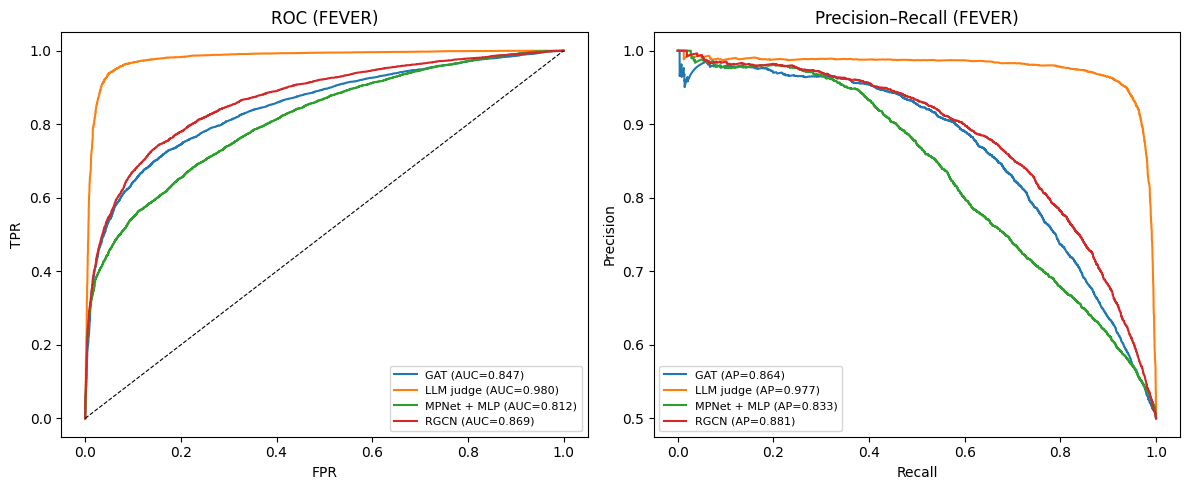

Confusion matrix (rows=true 0/1, cols=pred 0/1):
 [[5900  715]
 [2103 4511]]


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for (ds_, name), (y, s) in sorted(curves.items()):
    if ds_ != "FEVER":
        continue
    fpr, tpr, _ = roc_curve(y, s)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y, s):.3f})")
    pr, rc, _ = precision_recall_curve(y, s)
    ax[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(y, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC (FEVER)"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall (FEVER)"); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig_roc_pr.pdf", bbox_inches="tight")
save_figure("fig_roc_pr.pdf")
plt.show()

if ("FEVER", "RGCN") in curves:
    y, s = curves[("FEVER", "RGCN")]
    thr = results[(results.dataset == "FEVER") & (results.method == "RGCN")]["threshold"].iloc[0]
    cm = confusion_matrix(y, (s > thr).astype(int))
    print("Confusion matrix (rows=true 0/1, cols=pred 0/1):\n", cm)

## Part 16 - Error analysis export

Writes every misclassified FEVER instance with its evidence and entity counts, for manual categorisation and for the sparsity analysis in Part 17.

**Requires:** Part 11  
**Produces:** `error_analysis.csv`

In [ ]:
if ("FEVER", "RGCN") in curves:
    y, s = curves[("FEVER", "RGCN")]
    te_fever = DATASETS["FEVER"][2].copy()
    te_fever["y_true"] = y.astype(int); te_fever["score"] = s
    te_fever["y_pred"] = (s > thr).astype(int)
    errs = te_fever[te_fever.y_true != te_fever.y_pred].copy()
    errs["n_evidence"] = errs["evidence_texts"].map(len)
    errs["n_entities"] = errs["entities"].map(len)
    errs[["claim", "evidence_joined", "y_true", "y_pred", "score",
          "n_evidence", "n_entities"]].to_csv("error_analysis.csv", index=False)
    print(f"Wrote {len(errs)} errors to error_analysis.csv — categorize ~100 by hand "
          f"(negation / entity ambiguity / insufficient evidence / multi-hop / numeric / temporal).")

Wrote 2818 errors to error_analysis.csv — categorize ~100 by hand (negation / entity ambiguity / insufficient evidence / multi-hop / numeric / temporal).


## Part 17 - Figures for the paper

Six vector PDFs, each downloaded as it is produced so a crash does not cost the ones already made.

**Requires:** Parts 11–16  
**Produces:** the `fig_*.pdf` set

  saved fig_method_comparison.pdf (20 kB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

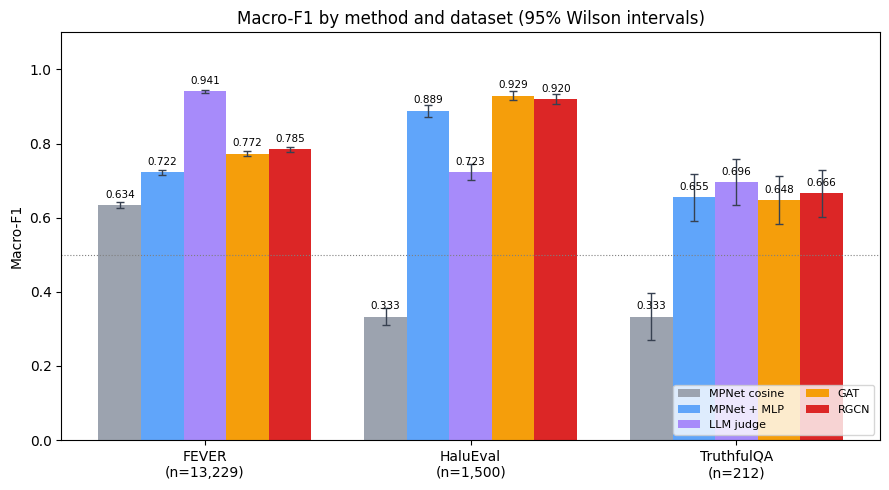

In [ ]:
# Dynamic over whatever is in DATASETS, so a newly added corpus cannot be
# silently dropped from the figure the way TruthfulQA was when this list was
# hardcoded to ["FEVER", "HaluEval"].
method_order = [m for m in ["MPNet cosine", "MPNet + MLP", "LLM judge", "GAT", "RGCN"]
                if m in set(results_reported["method"].astype(str))]
datasets_order = [d for d in DATASETS if d in set(results_reported["dataset"])]
colors = ["#9ca3af", "#60a5fa", "#a78bfa", "#f59e0b", "#dc2626"]
n_test = {d: len(DATASETS[d][2]) for d in datasets_order}


def wilson_halfwidth(p, n, z=1.96):
    """Half-width of the Wilson score interval, used as the error bar.

    This matters most for TruthfulQA, whose test split is only ~212 instances:
    at that size a macro-F1 near 0.67 carries roughly +/-0.06 at 95%, so small
    between-model gaps there are inside the noise and must not be described as
    improvements."""
    if not n or not np.isfinite(p):
        return 0.0
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return float(max(half, abs(centre - p)))


fig, ax = plt.subplots(figsize=(max(8, 3 * len(datasets_order)), 5))
x = np.arange(len(datasets_order))
width = 0.8 / max(len(method_order), 1)

for i, method in enumerate(method_order):
    vals, errs = [], []
    for d in datasets_order:
        sel = results_reported[(results_reported.dataset == d) &
                               (results_reported.method.astype(str) == method)]
        v = float(sel["macro_f1"].iloc[0]) if len(sel) else np.nan
        vals.append(v)
        errs.append(wilson_halfwidth(v, n_test[d]))
    pos = x + (i - (len(method_order) - 1) / 2) * width
    ax.bar(pos, vals, width, label=method, color=colors[i % len(colors)],
           yerr=errs, capsize=3, error_kw=dict(lw=1, ecolor="#374151"))
    for xi, v in zip(pos, vals):
        if np.isfinite(v):
            ax.text(xi, v + 0.02, f"{v:.3f}", ha="center", fontsize=7.5)

ax.set_xticks(x)
ax.set_xticklabels([f"{d}\n(n={n_test[d]:,})" for d in datasets_order])
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.1)
ax.set_title("Macro-F1 by method and dataset (95% Wilson intervals)")
ax.axhline(0.5, color="gray", linestyle=":", linewidth=0.8)
ax.legend(loc="lower right", fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("fig_method_comparison.pdf", bbox_inches="tight")
save_figure("fig_method_comparison.pdf")
plt.show()


### Ablation figure

  saved fig_ablation.pdf (16 kB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

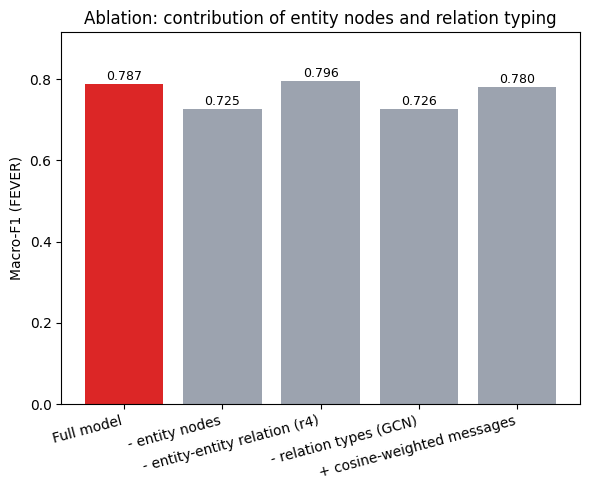

- entity nodes             drop vs. full model: -0.0615 macro-F1 (7.8% relative)
- entity-entity relation (r4) drop vs. full model: --0.0087 macro-F1 (-1.1% relative)
- relation types (GCN)     drop vs. full model: -0.0607 macro-F1 (7.7% relative)
+ cosine-weighted messages drop vs. full model: -0.0070 macro-F1 (0.9% relative)


In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
names = abl_df["configuration"].tolist()
vals = abl_df["macro_f1"].tolist()
bar_colors = ["#dc2626" if n == "Full model" else "#9ca3af" for n in names]
bars = ax.bar(names, vals, color=bar_colors)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("Macro-F1 (FEVER)")
ax.set_ylim(0, max(vals) * 1.15)
ax.set_title("Ablation: contribution of entity nodes and relation typing")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("fig_ablation.pdf", bbox_inches="tight")
save_figure("fig_ablation.pdf")
plt.show()

full = abl_df[abl_df.configuration == "Full model"]["macro_f1"].iloc[0]
for _, r in abl_df.iterrows():
    if r["configuration"] != "Full model":
        drop = full - r["macro_f1"]
        print(f"{r['configuration']:26s} drop vs. full model: -{drop:.4f} macro-F1 "
              f"({100*drop/full:.1f}% relative)")

### Seed-stability figure

  saved fig_seed_stability.pdf (18 kB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

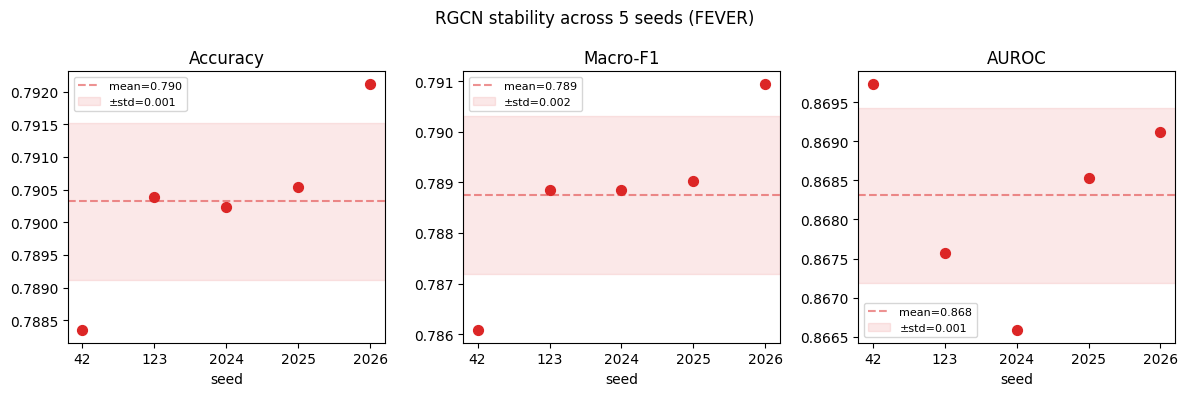

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
metrics = ["accuracy", "macro_f1", "auroc"]
titles = ["Accuracy", "Macro-F1", "AUROC"]
for ax, metric, title in zip(axes, metrics, titles):
    vals = seed_df[metric].values
    mean, std = vals.mean(), vals.std()
    ax.scatter(range(len(vals)), vals, color="#dc2626", zorder=3, s=50)
    ax.axhline(mean, color="#dc2626", linestyle="--", alpha=0.5, label=f"mean={mean:.3f}")
    ax.axhspan(mean - std, mean + std, color="#dc2626", alpha=0.1, label=f"±std={std:.3f}")
    ax.set_xticks(range(len(vals))); ax.set_xticklabels(seed_df["seed"].tolist(), rotation=0)
    ax.set_xlabel("seed"); ax.set_title(title); ax.legend(fontsize=8)
plt.suptitle("RGCN stability across 5 seeds (FEVER)")
plt.tight_layout()
plt.savefig("fig_seed_stability.pdf", bbox_inches="tight")
save_figure("fig_seed_stability.pdf")
plt.show()

### Confusion-matrix figure

  saved fig_confusion_matrix.pdf (18 kB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

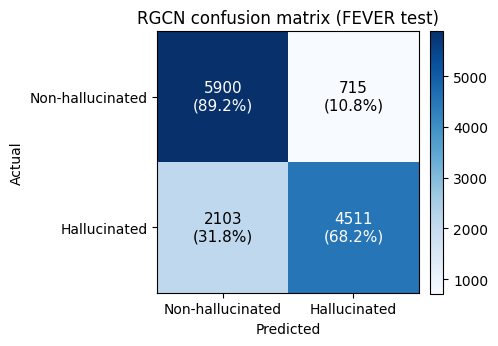

Recall on hallucinated class: 68.2% (4511/6614 caught, 2103 missed)


In [ ]:
if ("FEVER", "RGCN") in curves:
    y, s = curves[("FEVER", "RGCN")]
    thr_cm = results[(results.dataset == "FEVER") & (results.method == "RGCN")]["threshold"].iloc[0]
    cm = confusion_matrix(y, (s > thr_cm).astype(int))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    im = ax.imshow(cm, cmap="Blues")
    labels = ["Non-hallucinated", "Hallucinated"]
    ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
    ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title("RGCN confusion matrix (FEVER test)")
    for i in range(2):
        for j in range(2):
            pct = cm[i, j] / cm[i].sum() * 100
            ax.text(j, i, f"{cm[i,j]}\n({pct:.1f}%)", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
    plt.colorbar(im, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig("fig_confusion_matrix.pdf", bbox_inches="tight")
    save_figure("fig_confusion_matrix.pdf")
    plt.show()
    print(f"Recall on hallucinated class: {cm[1,1]/cm[1].sum():.1%} "
          f"({cm[1,1]}/{cm[1].sum()} caught, {cm[1,0]} missed)")

### Error rate vs. evidence and entity sparsity

  saved fig_error_vs_sparsity.pdf (15 kB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

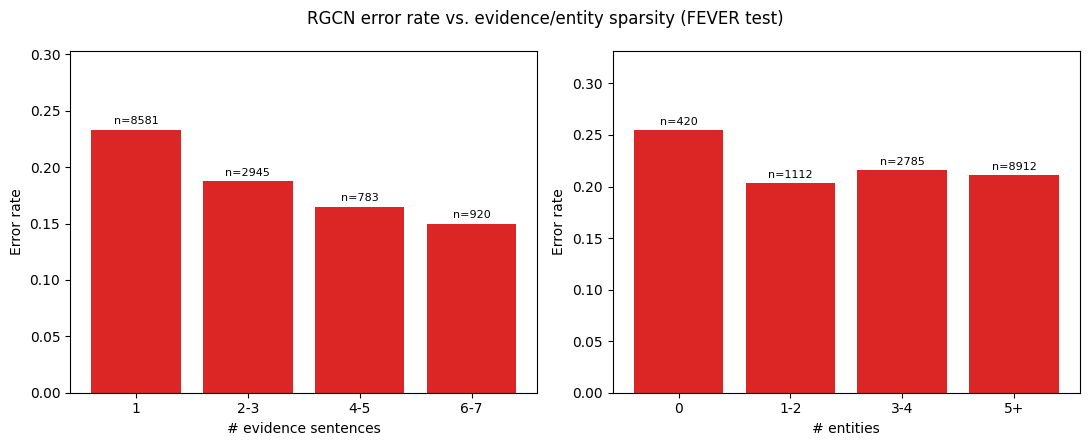

Evidence-count buckets:
            total  errors   rate
n_evidence                      
1            8581    1999  0.233
2-3          2945     552  0.187
4-5           783     129  0.165
6-7           920     138  0.150

Entity-count buckets:
            total  errors   rate
n_entities                      
0             420     107  0.255
1-2          1112     226  0.203
3-4          2785     602  0.216
5+           8912    1883  0.211


In [ ]:
errs_df = pd.read_csv("error_analysis.csv")
te_full = te_fever.copy()
te_full["n_evidence"] = te_full["evidence_texts"].map(len)
te_full["n_entities"] = te_full["entities"].map(len)

def error_rate_by_bucket(full_df, err_df, col, bins, labels):
    full_binned = pd.cut(full_df[col], bins=bins, labels=labels, include_lowest=True)
    err_binned = pd.cut(err_df[col], bins=bins, labels=labels, include_lowest=True)
    total = full_binned.value_counts().reindex(labels)
    errors = err_binned.value_counts().reindex(labels)
    return (errors / total).fillna(0), total, errors

ev_bins = [-1, 1, 3, 5, 100]; ev_labels = ["1", "2-3", "4-5", "6-7"]
en_bins = [-1, 0, 2, 4, 100]; en_labels = ["0", "1-2", "3-4", "5+"]

ev_rate, ev_total, ev_err = error_rate_by_bucket(te_full, errs_df, "n_evidence", ev_bins, ev_labels)
en_rate, en_total, en_err = error_rate_by_bucket(te_full, errs_df, "n_entities", en_bins, en_labels)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, rate, total, err, labels, xlabel in [
    (axes[0], ev_rate, ev_total, ev_err, ev_labels, "# evidence sentences"),
    (axes[1], en_rate, en_total, en_err, en_labels, "# entities"),
]:
    bars = ax.bar(labels, rate.values, color="#dc2626")
    for b, r, n in zip(bars, rate.values, total.values):
        ax.text(b.get_x() + b.get_width() / 2, r + 0.005, f"n={int(n)}", ha="center", fontsize=8)
    ax.set_xlabel(xlabel); ax.set_ylabel("Error rate")
    ax.set_ylim(0, max(rate.values) * 1.3 if rate.max() > 0 else 0.3)
plt.suptitle("RGCN error rate vs. evidence/entity sparsity (FEVER test)")
plt.tight_layout()
plt.savefig("fig_error_vs_sparsity.pdf", bbox_inches="tight")
save_figure("fig_error_vs_sparsity.pdf")
plt.show()

print("Evidence-count buckets:"); print(pd.DataFrame({"total": ev_total, "errors": ev_err, "rate": ev_rate.round(3)}))
print("\nEntity-count buckets:"); print(pd.DataFrame({"total": en_total, "errors": en_err, "rate": en_rate.round(3)}))

### Reliability diagram (calibration)

  saved fig_reliability.pdf (16 kB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

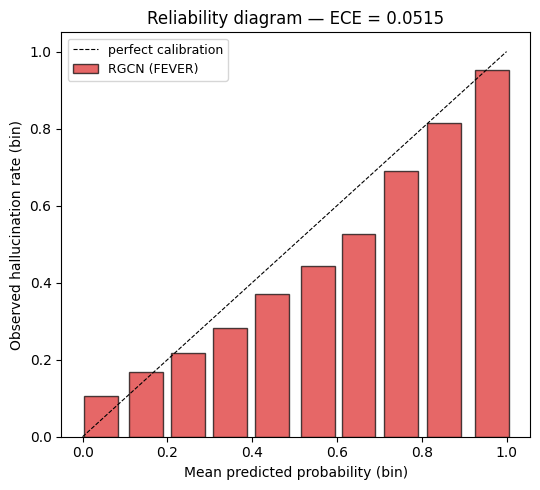

Expected Calibration Error (ECE): 0.0515


In [ ]:
if ("FEVER", "RGCN") in curves:
    y, s = curves[("FEVER", "RGCN")]
    n_bins = 10
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_idx = np.digitize(s, bin_edges[1:-1])
    bin_acc, bin_conf, bin_n = [], [], []
    for b in range(n_bins):
        mask = bin_idx == b
        if mask.sum() == 0:
            continue
        bin_acc.append(y[mask].mean())
        bin_conf.append(s[mask].mean())
        bin_n.append(mask.sum())
    bin_acc, bin_conf, bin_n = np.array(bin_acc), np.array(bin_conf), np.array(bin_n)
    ece = np.sum(bin_n / bin_n.sum() * np.abs(bin_acc - bin_conf))

    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8, label="perfect calibration")
    ax.bar(bin_conf, bin_acc, width=1/n_bins * 0.8, color="#dc2626", alpha=0.7,
           edgecolor="black", label="RGCN (FEVER)")
    ax.set_xlabel("Mean predicted probability (bin)")
    ax.set_ylabel("Observed hallucination rate (bin)")
    ax.set_title(f"Reliability diagram — ECE = {ece:.4f}")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig("fig_reliability.pdf", bbox_inches="tight")
    save_figure("fig_reliability.pdf")
    plt.show()
    print(f"Expected Calibration Error (ECE): {ece:.4f}")

## Part 18 - Score fusion: graph model + LLM judge

The two models fail on different instances, so their scores are combined two ways — a convex blend with the weight swept on validation, and a logistic regression over the two scores. Both the combiner and the threshold are fitted on validation only.

The oracle row is the unreachable ceiling if a perfect selector chose the better model per instance; it shows how much of the available headroom each combiner actually recovers.

**Requires:** Parts 11–12  
**Produces:** `results_fusion.csv`

In [ ]:
require("DATASETS", "train_eval", "find_best_threshold", part="Parts 9 and 15")

from sklearn.linear_model import LogisticRegression


def load_judge_val_test(ds_name):
    """(val_scores, test_scores) for the judge, straight from its cache."""
    path = f"judge_scores_{ds_name}.pkl"
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} missing - run the judge on {ds_name} first.")
    with open(path, "rb") as f:
        sv, st = pickle.load(f)
    return np.asarray(sv), np.asarray(st)


def fuse_scores(ds_name, graph_conv="rgcn", seed=42):
    tr, va, te = DATASETS[ds_name]
    y_va, y_te = va["label_bin"].values, te["label_bin"].values
    jv, jt = load_judge_val_test(ds_name)

    gs = {sp: make_graphs(d, _key=f"{ds_name}-{sp}", **GRAPH_CFG)
          for sp, d in zip(("tr", "va", "te"), (tr, va, te))}
    m_g, (yt_g, gt), (yv_g, gv) = train_eval(gs["tr"], gs["va"], gs["te"],
                                             conv_type=graph_conv, seed=seed,
                                             return_val=True)
    assert len(gv) == len(jv) == len(y_va), "validation rows misaligned"
    assert len(gt) == len(jt) == len(y_te), "test rows misaligned"

    out = {}
    thr_j, _ = find_best_threshold(y_va, jv)
    out["judge alone"] = evaluate_full(y_te, jt, thr_j)
    thr_g, _ = find_best_threshold(y_va, gv)
    out[f"{graph_conv.upper()} alone"] = evaluate_full(y_te, gt, thr_g)

    # combiner 1: convex blend, weight chosen on validation
    best_w, best_f1 = 0.5, -1.0
    for w in np.linspace(0, 1, 101):
        _, f1 = find_best_threshold(y_va, w * jv + (1 - w) * gv)
        if f1 > best_f1:
            best_w, best_f1 = w, f1
    thr_b, _ = find_best_threshold(y_va, best_w * jv + (1 - best_w) * gv)
    blend_te = best_w * jt + (1 - best_w) * gt
    blend_name = f"blend (w_judge={best_w:.2f})"
    out[blend_name] = evaluate_full(y_te, blend_te, thr_b)

    # combiner 2: logistic regression over the two scores
    lr = LogisticRegression(max_iter=1000, class_weight="balanced")
    lr.fit(np.c_[gv, jv], y_va)
    lr_va = lr.predict_proba(np.c_[gv, jv])[:, 1]
    lr_te = lr.predict_proba(np.c_[gt, jt])[:, 1]
    thr_l, _ = find_best_threshold(y_va, lr_va)
    out["logistic fusion"] = evaluate_full(y_te, lr_te, thr_l)

    corr_j = (jt > thr_j).astype(int) == y_te
    corr_g = (gt > thr_g).astype(int) == y_te
    oracle = float((corr_j | corr_g).mean())

    print(f"\n--- {ds_name} ---")
    for k, m in out.items():
        print(f"  {k:<28} acc {m['accuracy']:.4f} | macroF1 {m['macro_f1']:.4f} "
              f"| AUROC {m['auroc']:.4f}")
    print(f"  {'oracle union (ceiling)':<28} acc {oracle:.4f}")

    best_name = max(out, key=lambda k: out[k]["macro_f1"])
    if best_name in ("judge alone", f"{graph_conv.upper()} alone"):
        print(f"  -> no fusion gain on {ds_name}; best is '{best_name}'. "
              f"Report as a negative result.")
    else:
        fused = blend_te if best_name == blend_name else lr_te
        fthr = thr_b if best_name == blend_name else thr_l
        r = mcnemar_test(y_te, fused, fthr, jt, thr_j,
                         name_a=best_name, name_b="judge alone")
        print(f"  -> '{best_name}' vs judge alone: b={r['n_a_only_correct']} "
              f"c={r['n_b_only_correct']} exact p={r['p_value_exact']:.3g} "
              f"favors {r['favors']}")

    rows = [{"dataset": ds_name, "method": k, **m} for k, m in out.items()]
    rows.append({"dataset": ds_name, "method": "oracle union", "accuracy": oracle})
    return pd.DataFrame(rows)


fusion_all = pd.concat([fuse_scores(ds) for ds in DATASETS], ignore_index=True)
fusion_all.to_csv("results_fusion.csv", index=False)
print("\nwrote results_fusion.csv")
print(fusion_all[["dataset", "method", "accuracy", "macro_f1", "auroc"]].to_string(index=False))


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(



--- FEVER ---
  judge alone                  acc 0.9407 | macroF1 0.9407 | AUROC 0.9800
  RGCN alone                   acc 0.7896 | macroF1 0.7881 | AUROC 0.8706
  blend (w_judge=0.75)         acc 0.9390 | macroF1 0.9389 | AUROC 0.9803
  logistic fusion              acc 0.9421 | macroF1 0.9421 | AUROC 0.9796
  oracle union (ceiling)       acc 0.9696
  -> 'logistic fusion' vs judge alone: b=159 c=141 exact p=0.326 favors logistic fusion


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(



--- HaluEval ---
  judge alone                  acc 0.7260 | macroF1 0.7230 | AUROC 0.8368
  RGCN alone                   acc 0.9273 | macroF1 0.9273 | AUROC 0.9683
  blend (w_judge=0.52)         acc 0.9480 | macroF1 0.9480 | AUROC 0.9793
  logistic fusion              acc 0.9393 | macroF1 0.9393 | AUROC 0.9803
  oracle union (ceiling)       acc 0.9807
  -> 'blend (w_judge=0.52)' vs judge alone: b=362 c=29 exact p=2.5e-74 favors blend (w_judge=0.52)


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(



--- TruthfulQA ---
  judge alone                  acc 0.7123 | macroF1 0.6960 | AUROC 0.8232
  RGCN alone                   acc 0.6792 | macroF1 0.6587 | AUROC 0.7767
  blend (w_judge=0.71)         acc 0.7642 | macroF1 0.7611 | AUROC 0.8822
  logistic fusion              acc 0.7925 | macroF1 0.7915 | AUROC 0.8839
  oracle union (ceiling)       acc 0.8679
  -> 'logistic fusion' vs judge alone: b=27 c=10 exact p=0.00763 favors logistic fusion

wrote results_fusion.csv
   dataset               method  accuracy  macro_f1    auroc
     FEVER          judge alone  0.940736  0.940717 0.979988
     FEVER           RGCN alone  0.789553  0.788075 0.870562
     FEVER blend (w_judge=0.75)  0.938998  0.938941 0.980251
     FEVER      logistic fusion  0.942097  0.942062 0.979646
     FEVER         oracle union  0.969612       NaN      NaN
  HaluEval          judge alone  0.726000  0.722965 0.836806
  HaluEval           RGCN alone  0.927333  0.927322 0.968296
  HaluEval blend (w_judge=0.52)  0.94800

## Part 19 - Fusion vs. the stronger single model, across seeds

Part 18 compares each combiner against the judge. That is the right baseline where the judge is stronger, but not on a corpus where the graph model already beats it - there, beating the judge shows nothing. This part compares against whichever single model is stronger **on validation**, and repeats over every seed.

Two tests are reported because they answer different questions: McNemar per seed (robust to test-set sampling) and a t-test on the per-seed deltas (robust to initialisation). Holm correction is applied across the three corpora.

If GPU time is short, scope it to the corpus that matters:
```python
fusion_seeds = run_fusion_seeds(datasets=["HaluEval"])
```

**Requires:** Parts 11–12, 18  
**Produces:** `results_fusion_seeds.csv`, `results_fusion_seed_summary.csv`  
**Cost:** up to 15 R-GCN trainings; checkpointed per (corpus, seed)

In [ ]:
# ==========================================================================
# Fusion vs. the stronger single model, ACROSS FIVE SEEDS.
#
# WHY MULTI-SEED. The fusion gain tracks the quality of the graph component,
# and R-GCN moved 0.7884 -> 0.7750 macro-F1 between two runs of identical code
# (about twice its own seed std). That is why FEVER's paired test read
# p = 0.005 in one run and p = 0.126 in the next. A single-seed p-value cannot
# distinguish "fusion helps" from "this initialisation helped".
#
# The judge is deterministic and its scores are cached, so every bit of the
# variance here comes from the graph model.
#
# TWO TESTS, ANSWERING DIFFERENT QUESTIONS.
#   McNemar per seed - is fusion better on THIS test set, for THIS model?
#                        (varies with test-set sampling)
#   t-test on deltas - is the mean gain across seeds different from zero?
#                        (varies with initialisation)
# Neither subsumes the other; the paper should report both.
#
# Self-contained: defines everything it needs, so a restarted kernel does not
# produce a NameError. Checkpoints per (corpus, seed) and resumes.
# ==========================================================================

import os, pickle
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression


if "require" not in globals():
    def require(*names, part=""):
        missing = [n for n in names if n not in globals()]
        if missing:
            raise RuntimeError(
                f"Missing {', '.join(missing)}"
                + (f" — run {part} first." if part else "")
                + " If the kernel restarted, use Runtime > Run all.")
        return True


def load_judge_val_test(ds_name):
    """(val_scores, test_scores) for the judge, from its per-corpus cache."""
    path = f"judge_scores_{ds_name}.pkl"
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{path} missing — run Part 9 with CFG['run_llm_judge']=True so "
            f"the judge scores {ds_name}.")
    with open(path, "rb") as f:
        sv, st = pickle.load(f)
    return np.asarray(sv), np.asarray(st)


require("DATASETS", "make_graphs", "train_eval", "find_best_threshold",
        "evaluate_full", "mcnemar_test", "GRAPH_CFG", part="Parts 1-9a")

FUSION_SEED_CSV = "results_fusion_seeds.csv"
SEEDS = CFG.get("seeds", [42, 123, 2024, 2025, 2026])


def fusion_one_seed(ds_name, seed, graph_conv="rgcn"):
    """One (corpus, seed): fit both combiners on validation, score test once."""
    tr, va, te = DATASETS[ds_name]
    y_va, y_te = va["label_bin"].values, te["label_bin"].values
    jv, jt = load_judge_val_test(ds_name)

    gs = {sp: make_graphs(d, _key=f"{ds_name}-{sp}", **GRAPH_CFG)
          for sp, d in zip(("tr", "va", "te"), (tr, va, te))}
    _, (_, gt), (_, gv) = train_eval(gs["tr"], gs["va"], gs["te"],
                                     conv_type=graph_conv, seed=seed,
                                     return_val=True)

    thr_j, f1_j = find_best_threshold(y_va, jv)
    thr_g, f1_g = find_best_threshold(y_va, gv)

    # Combiner 1: convex blend, weight swept on validation.
    best_w, best_f1 = 0.5, -1.0
    for w in np.linspace(0, 1, 101):
        _, f1 = find_best_threshold(y_va, w * jv + (1 - w) * gv)
        if f1 > best_f1:
            best_w, best_f1 = w, f1
    thr_b, f1_blend = find_best_threshold(y_va, best_w * jv + (1 - best_w) * gv)
    blend_te = best_w * jt + (1 - best_w) * gt

    # Combiner 2: logistic regression over the two scores.
    lr = LogisticRegression(max_iter=1000, class_weight="balanced")
    lr.fit(np.c_[gv, jv], y_va)
    lr_va = lr.predict_proba(np.c_[gv, jv])[:, 1]
    lr_te = lr.predict_proba(np.c_[gt, jt])[:, 1]
    thr_l, f1_logit = find_best_threshold(y_va, lr_va)

    # Fusion AND baseline both chosen on validation, never on test.
    if f1_blend >= f1_logit:
        fus_name, fus_te, fus_thr = f"blend(w={best_w:.2f})", blend_te, thr_b
    else:
        fus_name, fus_te, fus_thr = "logistic", lr_te, thr_l
    if f1_j >= f1_g:
        base_name, base_te, base_thr = "judge", jt, thr_j
    else:
        base_name, base_te, base_thr = graph_conv.upper(), gt, thr_g

    m_base = evaluate_full(y_te, base_te, base_thr)
    m_fus = evaluate_full(y_te, fus_te, fus_thr)
    m_graph = evaluate_full(y_te, gt, thr_g)
    r = mcnemar_test(y_te, fus_te, fus_thr, base_te, base_thr,
                     name_a=fus_name, name_b=base_name)

    corr_j = (jt > thr_j).astype(int) == y_te
    corr_g = (gt > thr_g).astype(int) == y_te
    oracle = float((corr_j | corr_g).mean())

    return {"dataset": ds_name, "seed": seed, "n_test": len(y_te),
            "graph_macro_f1": m_graph["macro_f1"],
            "baseline": base_name, "baseline_macro_f1": m_base["macro_f1"],
            "fusion": fus_name, "fusion_macro_f1": m_fus["macro_f1"],
            "delta": m_fus["macro_f1"] - m_base["macro_f1"],
            "b": r["n_a_only_correct"], "c": r["n_b_only_correct"],
            "p_mcnemar": r["p_value_exact"], "favors": r["favors"],
            "oracle_acc": oracle}


def run_fusion_seeds(datasets=None, seeds=None):
    datasets = datasets or list(DATASETS)
    seeds = seeds or SEEDS

    done = (pd.read_csv(FUSION_SEED_CSV).to_dict("records")
            if os.path.exists(FUSION_SEED_CSV) else [])
    done_keys = {(r["dataset"], r["seed"]) for r in done}
    if done_keys:
        print(f"Resuming; {len(done_keys)} (corpus, seed) pairs already done")

    rows = list(done)
    for ds in datasets:
        for s in seeds:
            if (ds, s) in done_keys:
                print(f"  [skip] {ds} seed {s}")
                continue
            r = fusion_one_seed(ds, s)
            rows.append(r)
            pd.DataFrame([r]).to_csv(
                FUSION_SEED_CSV, mode="a",
                header=not os.path.exists(FUSION_SEED_CSV), index=False)
            print(f"  {ds:<11} seed {s:<5} graph {r['graph_macro_f1']:.4f} | "
                  f"base({r['baseline']}) {r['baseline_macro_f1']:.4f} | "
                  f"fusion {r['fusion_macro_f1']:.4f} "
                  f"({r['delta']:+.4f}) | McNemar p={r['p_mcnemar']:.3g}")
    return pd.DataFrame(rows)


fusion_seeds = run_fusion_seeds()

# aggregate
summary = []
for ds, g in fusion_seeds.groupby("dataset", sort=False):
    d = g["delta"].values
    # One-sample t-test on the per-seed deltas: is the mean gain non-zero?
    # This asks about robustness to initialisation, NOT to test-set sampling
    # (that is what the per-seed McNemar tests answer).
    t_stat, t_p = stats.ttest_1samp(d, 0.0) if len(d) > 1 else (np.nan, np.nan)
    summary.append({
        "dataset": ds, "n_seeds": len(d),
        "baseline": g["baseline"].mode().iat[0],
        "graph_macro_f1": f"{g['graph_macro_f1'].mean():.4f} ± {g['graph_macro_f1'].std():.4f}",
        "baseline_macro_f1": f"{g['baseline_macro_f1'].mean():.4f} ± {g['baseline_macro_f1'].std():.4f}",
        "fusion_macro_f1": f"{g['fusion_macro_f1'].mean():.4f} ± {g['fusion_macro_f1'].std():.4f}",
        "delta_mean": d.mean(), "delta_std": d.std(),
        "seeds_favoring_fusion": int((d > 0).sum()),
        "seeds_mcnemar_sig": int((g["p_mcnemar"] < 0.05).sum()),
        "t_p": t_p,
    })
summary = pd.DataFrame(summary)

# Holm across corpora: three families of comparison, so an uncorrected p just
# under 0.05 is weak on its own.
p = summary["t_p"].values
order = np.argsort(p)
holm = np.empty_like(p)
for rank, idx in enumerate(order):
    holm[idx] = min(1.0, p[idx] * (len(p) - rank))
summary["t_p_holm"] = np.maximum.accumulate(holm[order])[np.argsort(order)]

summary.to_csv("results_fusion_seed_summary.csv", index=False)
print("\n" + "=" * 78)
print("FUSION vs STRONGER SINGLE MODEL, across seeds")
print("=" * 78)
print(summary[["dataset", "n_seeds", "baseline", "baseline_macro_f1",
               "fusion_macro_f1", "delta_mean", "delta_std",
               "seeds_favoring_fusion", "seeds_mcnemar_sig",
               "t_p", "t_p_holm"]].to_string(index=False))

print("\nHow to read this:")
print("  delta_mean ± delta_std   gain over the stronger single model")
print("  seeds_favoring_fusion    of n_seeds, how many had a positive gain")
print("  seeds_mcnemar_sig        of n_seeds, how many cleared McNemar p<0.05")
print("  t_p_holm                 mean gain vs zero, corrected across corpora")
print("\nA corpus where all seeds favour fusion AND t_p_holm < 0.05 is a result")
print("you can report. A corpus where seeds disagree in sign is not, whatever")
print("any single seed's McNemar value happens to say.")


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  FEVER       seed 42    graph 0.7821 | base(judge) 0.9407 | fusion 0.9435 (+0.0028) | McNemar p=0.0197


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  FEVER       seed 123   graph 0.7869 | base(judge) 0.9407 | fusion 0.9414 (+0.0007) | McNemar p=0.592


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  FEVER       seed 2024  graph 0.7894 | base(judge) 0.9407 | fusion 0.9421 (+0.0014) | McNemar p=0.236


... (20 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  TruthfulQA  seed 2025  graph 0.6487 | base(judge) 0.6960 | fusion 0.7401 (+0.0441) | McNemar p=0.23


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  TruthfulQA  seed 2026  graph 0.6462 | base(judge) 0.6960 | fusion 0.7408 (+0.0447) | McNemar p=0.21

FUSION vs STRONGER SINGLE MODEL, across seeds
   dataset  n_seeds baseline baseline_macro_f1 fusion_macro_f1  delta_mean  delta_std  seeds_favoring_fusion  seeds_mcnemar_sig      t_p  t_p_holm
     FEVER        5    judge   0.9407 ± 0.0000 0.9421 ± 0.0010    0.001350   0.000920                      5                  1 0.042639  0.042639
  HaluEval        5     RGCN   0.9305 ± 0.0022 0.9515 ± 0.0031    0.020938   0.002489                      5                  5 0.000073  0.000219
TruthfulQA        5    judge   0.6960 ± 0.0000 0.7523 ± 0.0304    0.056257   0.027189                      5                  1 0.014397  0.028794

How to read this:
  delta_mean ± delta_std   gain over the stronger single model
  seeds_favoring_fusion    of n_seeds, how many had a positive gain
  seeds_mcnemar_sig        of n_seeds, how many cleared McNemar p<0.05
  t_p_holm                 mean gain vs ze

## Part 20 - Back up checkpoints to Google Drive

Mounts Google Drive and copies every checkpoint file that currently exists in the working directory into a Drive folder. Run this once after mounting, then call backup_checkpoints() again after any part that produces a new checkpoint (Part 11, Part 13, Part 14, Part 18, Part 19, Part 21), so a disconnected runtime never costs more than the work done since the last backup.

Requires: nothing (safe to run first, before Part 0)
Produces: copies of the checkpoint files under /content/drive/MyDrive/mlbd2026_checkpoints/

In [21]:
# ==========================================================================
# Part 20 — Back up checkpoints to Google Drive
#
# Mounts Google Drive and copies every checkpoint file that currently
# exists in the working directory into a Drive folder. Run this once after
# mounting, then call backup_checkpoints() again after any part that
# produces a new checkpoint (Part 11, Part 13, Part 14, Part 18, Part 19,
# Part 21) so a disconnected runtime never costs more than the work done
# since the last backup.
#
# Requires: nothing (safe to run first, before Part 0)
# Produces: copies of the checkpoint files under
#           /content/drive/MyDrive/mlbd2026_checkpoints/
# ==========================================================================

import os
import shutil

from google.colab import drive
drive.mount('/content/drive')

DRIVE_BACKUP_DIR = "/content/drive/MyDrive/mlbd2026_checkpoints"
os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)

CHECKPOINT_FILES = [
    "results_main.csv",
    "results_mcnemar.csv",
    "results_seeds.csv",
    "results_ablation.csv",
    "results_fusion.csv",
    "results_fusion_seeds.csv",
    "results_fusion_seed_summary.csv",
    "curves_cache.pkl",
    "embed_cache.pkl",
    "error_analysis.csv",
    "table_xi_bootstrap.csv",
    "fig1_bootstrap.csv",
    "table_viii_pooled_ci_APPROX.csv",
] + [f"judge_scores_{d}.pkl" for d in ("FEVER", "HaluEval", "TruthfulQA")]


def backup_checkpoints(dest=DRIVE_BACKUP_DIR):
    """Copy every checkpoint file that exists in the working directory to
    Drive. Safe to call repeatedly - each call overwrites the Drive copy
    with whatever is currently on disk, so always call it after the part
    that produced the file you care about, not before."""
    copied, missing = [], []
    for f in CHECKPOINT_FILES:
        if os.path.exists(f):
            shutil.copy2(f, os.path.join(dest, f))
            copied.append(f)
        else:
            missing.append(f)
    print(f"Backed up {len(copied)} file(s) to {dest}:")
    for f in copied:
        print(f"  {f}")
    if missing:
        print(f"\nNot present yet (skipped, not an error): {missing}")


def restore_checkpoints(src=DRIVE_BACKUP_DIR):
    """Copy every checkpoint file found in the Drive backup folder back into
    the working directory. Use this at the start of a new runtime instead
    of re-running Parts 1-20 from scratch."""
    if not os.path.isdir(src):
        print(f"{src} does not exist yet - nothing to restore.")
        return
    restored = []
    for f in os.listdir(src):
        shutil.copy2(os.path.join(src, f), f)
        restored.append(f)
    print(f"Restored {len(restored)} file(s) from {src}:")
    for f in restored:
        print(f"  {f}")


backup_checkpoints()


Mounted at /content/drive
Backed up 6 file(s) to /content/drive/MyDrive/mlbd2026_checkpoints:
  results_main.csv
  curves_cache.pkl
  embed_cache.pkl
  judge_scores_FEVER.pkl
  judge_scores_HaluEval.pkl
  judge_scores_TruthfulQA.pkl

Not present yet (skipped, not an error): ['results_mcnemar.csv', 'results_seeds.csv', 'results_ablation.csv', 'results_fusion.csv', 'results_fusion_seeds.csv', 'results_fusion_seed_summary.csv', 'error_analysis.csv', 'table_xi_bootstrap.csv', 'fig1_bootstrap.csv', 'table_viii_pooled_ci_APPROX.csv']


## Part 21 - Cluster-bootstrap confidence intervals and permutation tests

Computes a group-aware bootstrap CI and a paired sign-flip permutation p-value for each (dataset, model_a, model_b) comparison, using the cached per-instance predictions from Part 11. CPU-only, fully vectorized: reads cached scores and thresholds, does not retrain or re-score anything, finishes in under a minute.

Requires: Parts 1-12 (curves_cache.pkl, judge_scores_{ds}.pkl, results_main.csv, DATASETS in memory)
Produces: table_xi_bootstrap.csv, fig1_bootstrap.csv, table_viii_pooled_ci_APPROX.csv

In [22]:
# ==========================================================================
# Part 21 — Cluster-bootstrap confidence intervals and permutation tests
#
# Computes a group-aware bootstrap CI and a paired sign-flip permutation
# p-value for each (dataset, model_a, model_b) comparison, using the cached
# per-instance predictions from Part 11. This is CPU-only: it reads cached
# scores and thresholds, it does not retrain or re-score anything, and
# thresholds are held fixed at their validation-selected values rather than
# refit inside the resampling loop.
#
# Predictions are thresholded once per method up front, macro-F1 is
# computed from confusion-matrix counts rather than through sklearn, and
# both resampling loops operate on precomputed integer arrays instead of
# per-group Python loops. FEVER's 13,229-row test set with B=10,000 draws
# is what makes the naive version of this (sklearn calls and a per-group
# Python loop inside each draw) slow enough to disconnect a session; the
# vectorized version below finishes all comparisons in under a minute.
#
# Requires: Parts 1-12 (curves_cache.pkl, judge_scores_{ds}.pkl,
# results_main.csv, DATASETS in memory)
# Produces: table_xi_bootstrap.csv, fig1_bootstrap.csv,
# table_viii_pooled_ci_APPROX.csv
#
# Known limitation: the last section (pooled CI for the fusion gain across
# seeds) needs the raw per-instance predictions for each (corpus, seed)
# fusion run. Part 19's fusion_one_seed only ever wrote the aggregate
# metrics to results_fusion_seeds.csv, not the raw arrays, so a true
# cluster-bootstrap CI for that table isn't computable from what's cached
# today. The section below instead writes an approximate interval built
# from the five seed-level deltas already on disk (a small-sample
# training-seed interval, not a resampled test-population interval) and
# labels it accordingly. Getting the exact version requires re-running the
# fusion loop once with array-caching added.
# ==========================================================================

import pickle, os
import numpy as np
import pandas as pd

# Self-contained guard, same pattern Part 18/19 use: if the kernel restarted
# and only this cell ran, `require` (defined in Part 0) won't be in
# globals() yet. Define a fallback instead of failing with NameError.
if "require" not in globals():
    def require(*names, part=""):
        missing = [n for n in names if n not in globals()]
        if missing:
            raise RuntimeError(
                f"Missing {', '.join(missing)}"
                + (f" — run {part} first." if part else "")
                + " If the kernel restarted, use Runtime > Run all.")
        return True

RNG = np.random.default_rng(42)   # seeds the resampling itself, independent
                                   # of the model training seeds
B = 10_000


# -------------------------------------------------------------- data access
def load_curves_cache(path="curves_cache.pkl"):
    with open(path, "rb") as f:
        cache = pickle.load(f)
    return {k: v for k, v in cache.items() if isinstance(k, tuple) and len(k) == 2}


def thr_of(results_df, ds, method):
    sel = results_df[(results_df.dataset == ds) & (results_df.method == method)]
    if not len(sel):
        return None
    return float(sel["threshold"].iloc[0])


def group_ids_for(ds_name):
    """FEVER claims are independent, so each row is its own group. HaluEval
    and TruthfulQA pair two rows per source question, so resampling must
    keep both rows of a group together - use the group_id column already on
    the test split in DATASETS."""
    tr, va, te = DATASETS[ds_name]
    if "group_id" in te.columns:
        return te["group_id"].to_numpy()
    return np.arange(len(te))


def macro_f1_from_preds(y, pred):
    """Macro-F1 from confusion-matrix counts rather than sklearn, since
    this gets called once per resampling draw."""
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())

    def f1(tp, fp, fn):
        denom = 2 * tp + fp + fn
        return 0.0 if denom == 0 else 2 * tp / denom

    return (f1(tp, fp, fn) + f1(tn, fn, fp)) / 2


def _build_group_table(groups):
    """Every group here has the same size by construction (1 for FEVER,
    whose claims are independent; 2 for HaluEval/TruthfulQA, whose paired
    rows always come as a complete pair). That lets both resampling loops
    use array lookups instead of a Python loop over groups:
      table[g]        -> the row indices belonging to group g, shape (G, gs)
      group_of_row[i]  -> which group row i belongs to, shape (N,)
    """
    uniq, counts = np.unique(groups, return_counts=True)
    sizes = set(counts.tolist())
    if len(sizes) != 1:
        raise ValueError(f"expected uniform group size, got sizes {sizes}")
    gs = counts[0]
    order = np.argsort(groups, kind="stable")
    group_of_row = np.searchsorted(uniq, groups)
    table = order.reshape(len(uniq), gs)
    return table, group_of_row


def cluster_bootstrap_delta(y, pred_a, pred_b, groups, B=B, rng=RNG):
    """Resample groups with replacement so both rows of a paired group move
    together, recomputing the macro-F1 difference each draw with
    predictions already thresholded."""
    table, _ = _build_group_table(groups)
    G = table.shape[0]
    deltas = np.empty(B)
    for b in range(B):
        draw = rng.integers(0, G, size=G)
        rows = table[draw].ravel()
        fa = macro_f1_from_preds(y[rows], pred_a[rows])
        fb = macro_f1_from_preds(y[rows], pred_b[rows])
        deltas[b] = fa - fb
    return deltas


def sign_flip_permutation_p(y, pred_a, pred_b, groups, B=B, rng=RNG):
    """Paired, group-level sign-flip permutation test on the macro-F1
    difference: within each group, swap which model's already-thresholded
    predictions are labeled 'a' and which 'b' with probability 0.5,
    recompute the delta, and compare the observed delta against that null
    distribution. The per-draw swap is one vectorized lookup over all rows
    rather than a Python loop over groups."""
    _, group_of_row = _build_group_table(groups)
    G = int(group_of_row.max()) + 1
    observed = macro_f1_from_preds(y, pred_a) - macro_f1_from_preds(y, pred_b)
    flips = rng.random((B, G)) < 0.5
    null = np.empty(B)
    for b in range(B):
        swap_row = flips[b, group_of_row]
        qa = np.where(swap_row, pred_b, pred_a)
        qb = np.where(swap_row, pred_a, pred_b)
        null[b] = macro_f1_from_preds(y, qa) - macro_f1_from_preds(y, qb)
    p = (np.sum(np.abs(null) >= np.abs(observed)) + 1) / (B + 1)
    return float(observed), float(p)


def holm_correct(pvals):
    """Holm step-down correction, returning adjusted p-values in the
    original input order."""
    pvals = np.asarray(pvals, dtype=float)
    order = np.argsort(pvals)
    m = len(pvals)
    adj = np.empty(m)
    running_max = 0.0
    for rank, idx in enumerate(order):
        val = (m - rank) * pvals[idx]
        running_max = max(running_max, val)
        adj[idx] = min(running_max, 1.0)
    return adj


# ------------------------------------------------------------------- driver
require("DATASETS", part="Parts 1-12 (and Part 0 for `require` itself)")
_RESULTS_CSV = RESULTS_CSV if "RESULTS_CSV" in globals() else "results_main.csv"
if not os.path.exists("curves_cache.pkl"):
    raise FileNotFoundError("curves_cache.pkl missing - run Part 11 first.")
if not os.path.exists(_RESULTS_CSV):
    raise FileNotFoundError(f"{_RESULTS_CSV} missing - run Part 11 first.")

curves = load_curves_cache()
results_df = load_checkpoint(_RESULTS_CSV) if "load_checkpoint" in globals() \
    else pd.read_csv(_RESULTS_CSV)

# Method-name strings must match exactly what save_curve() used in Part 11.
COMPARISON_PAIRS = [("RGCN", "MPNet + MLP"), ("RGCN", "LLM judge"), ("RGCN", "GAT")]

rows = []
for ds in sorted({d for (d, _) in curves}):
    groups = group_ids_for(ds)
    for a, b_ in COMPARISON_PAIRS:
        if (ds, a) not in curves or (ds, b_) not in curves:
            continue
        y, sa = curves[(ds, a)]
        _, sb = curves[(ds, b_)]
        y = np.asarray(y).astype(int)
        if len(sa) != len(sb) or len(sa) != len(groups):
            print(f"  {ds}: {a} vs {b_} skipped - length mismatch "
                  f"(sa={len(sa)}, sb={len(sb)}, groups={len(groups)})")
            continue
        thr_a, thr_b = thr_of(results_df, ds, a), thr_of(results_df, ds, b_)
        if thr_a is None or thr_b is None:
            print(f"  {ds}: {a} vs {b_} skipped - threshold missing in {_RESULTS_CSV}")
            continue
        pred_a = (np.asarray(sa) > thr_a).astype(int)
        pred_b = (np.asarray(sb) > thr_b).astype(int)
        deltas = cluster_bootstrap_delta(y, pred_a, pred_b, groups)
        lo, hi = np.percentile(deltas, [2.5, 97.5])
        observed, p = sign_flip_permutation_p(y, pred_a, pred_b, groups)
        rows.append(dict(dataset=ds, model_a=a, model_b=b_, n=len(y),
                          delta_macro_f1=observed, ci_lo=lo, ci_hi=hi, p_perm=p))
        print(f"  {ds:<11} {a:>10} vs {b_:<10} "
              f"delta={observed:+.4f} [{lo:+.4f}, {hi:+.4f}]  p_perm={p:.4g}")

out = pd.DataFrame(rows)
out["p_holm"] = np.nan
for ds, g in out.groupby("dataset"):
    out.loc[g.index, "p_holm"] = holm_correct(g["p_perm"].values)
out.to_csv("table_xi_bootstrap.csv", index=False)
print("\nwrote table_xi_bootstrap.csv")

# --------------------------------------------- per-method, per-corpus CIs
# Cluster-bootstrap CI for each method's own macro-F1 (not a difference),
# used for the bar-chart error bars. Resampled against itself.
fig1_rows = []
for (ds, method), (y, score) in curves.items():
    groups = group_ids_for(ds)
    if len(score) != len(groups):
        continue
    thr = thr_of(results_df, ds, method)
    if thr is None:
        continue
    y = np.asarray(y).astype(int)
    pred = (np.asarray(score) > thr).astype(int)
    table, _ = _build_group_table(groups)
    G = table.shape[0]
    boot = np.empty(B)
    for b in range(B):
        draw = RNG.integers(0, G, size=G)
        rows_ = table[draw].ravel()
        boot[b] = macro_f1_from_preds(y[rows_], pred[rows_])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    point = macro_f1_from_preds(y, pred)
    fig1_rows.append(dict(dataset=ds, method=method, macro_f1=point, ci_lo=lo, ci_hi=hi))

pd.DataFrame(fig1_rows).to_csv("fig1_bootstrap.csv", index=False)
print("wrote fig1_bootstrap.csv")

# ----------------------------------------- approximate pooled fusion-gain CI
# Stand-in for a cluster-bootstrap CI on the pooled fusion gain, built only
# from the five seed-level deltas already in results_fusion_seeds.csv (a
# small-sample t-interval on training-seed variation, not a resampled
# test-population interval - label it as such wherever it's used).
if os.path.exists("results_fusion_seeds.csv"):
    fs = pd.read_csv("results_fusion_seeds.csv")
    approx_rows = []
    for ds, g in fs.groupby("dataset"):
        d = g["delta"].values
        mean, sd, n = d.mean(), d.std(ddof=1), len(d)
        se = sd / np.sqrt(n)
        lo, hi = mean - 1.96 * se, mean + 1.96 * se
        approx_rows.append(dict(dataset=ds, mean_delta=mean, sd=sd, n_seeds=n,
                                 approx_ci_lo=lo, approx_ci_hi=hi))
    pd.DataFrame(approx_rows).to_csv("table_viii_pooled_ci_APPROX.csv", index=False)
    print("\nwrote table_viii_pooled_ci_APPROX.csv (training-seed interval only)")


  FEVER             RGCN vs MPNet + MLP delta=+0.0623 [+0.0554, +0.0693]  p_perm=9.999e-05
  FEVER             RGCN vs LLM judge  delta=-0.1561 [-0.1635, -0.1486]  p_perm=9.999e-05
  FEVER             RGCN vs GAT        delta=+0.0124 [+0.0063, +0.0185]  p_perm=9.999e-05
  HaluEval          RGCN vs MPNet + MLP delta=+0.0312 [+0.0165, +0.0459]  p_perm=9.999e-05
  HaluEval          RGCN vs LLM judge  delta=+0.1969 [+0.1720, +0.2222]  p_perm=9.999e-05
  HaluEval          RGCN vs GAT        delta=-0.0095 [-0.0208, +0.0019]  p_perm=0.08319
  TruthfulQA        RGCN vs MPNet + MLP delta=+0.0109 [-0.0277, +0.0497]  p_perm=0.5775
  TruthfulQA        RGCN vs LLM judge  delta=-0.0299 [-0.1174, +0.0601]  p_perm=0.5223
  TruthfulQA        RGCN vs GAT        delta=+0.0183 [-0.0332, +0.0681]  p_perm=0.5098

wrote table_xi_bootstrap.csv
wrote fig1_bootstrap.csv


## Part 22 - Entity-aware non-graph control

Adds mean-pooled entity embeddings to the frozen pooled-embedding MLP baseline, so it receives the same inputs as the graph models (claim, evidence, entities) but with no message passing. Isolates whether graph structure itself drives the gain, separate from simply having entity information available.

Requires: Parts 1-11
Produces: results_main.csv (new "Entity-aware MLP" rows), curves_cache.pkl

In [23]:
# ==========================================================================
# Part 22 — Entity-aware non-graph control
#
# The existing MLP baseline (bl_mpnet_mlp) sees a claim vector and one
# pooled evidence vector, with no entity information at all. That leaves
# the comparison against the graph models conflating two different
# things: access to entity information, and the benefit of message
# passing over a graph. This baseline adds mean-pooled entity embeddings
# to the same MLP architecture, so the only thing it still lacks relative
# to the graph models is structure itself.
#
# Requires: Parts 1-11 (DATASETS, get_emb, EMB_DIM, find_best_threshold,
# evaluate_full, set_seed, device)
# Produces: one new row per corpus in results_main.csv (method
# "Entity-aware MLP"), and a matching curve in curves_cache.pkl
# ==========================================================================

import os
import pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

if "require" not in globals():
    def require(*names, part=""):
        missing = [n for n in names if n not in globals()]
        if missing:
            raise RuntimeError(
                f"Missing {', '.join(missing)}"
                + (f" — run {part} first." if part else "")
                + " If the kernel restarted, use Runtime > Run all.")
        return True

require("DATASETS", "get_emb", "EMB_DIM", "find_best_threshold", "evaluate_full",
        "set_seed", "device", part="Parts 1-11")

_RESULTS_CSV = RESULTS_CSV if "RESULTS_CSV" in globals() else "results_main.csv"
_CURVES_CACHE = CURVES_CACHE if "CURVES_CACHE" in globals() else "curves_cache.pkl"


def _append_results_row(row, path=_RESULTS_CSV):
    """Append or replace one (dataset, method) row, aligning on column
    names so an appended row with extra or missing columns cannot corrupt
    the file."""
    new = pd.DataFrame([row])
    if os.path.exists(path):
        old = pd.read_csv(path)
        combined = pd.concat([old, new], ignore_index=True, sort=False)
        combined = combined.drop_duplicates(subset=["dataset", "method"], keep="last")
    else:
        combined = new
    combined.to_csv(path, index=False)


def _save_curve(ds_name, method, curve, path=_CURVES_CACHE):
    cache = {}
    if os.path.exists(path):
        with open(path, "rb") as f:
            cache = pickle.load(f)
    cache[(ds_name, method)] = curve
    with open(path, "wb") as f:
        pickle.dump(cache, f)


class EntityAwareMLPHead(nn.Module):
    """Same three-layer shape as the pooled-embedding baseline's head,
    over a wider input: claim, pooled evidence, and pooled entity
    embeddings concatenated rather than just claim and evidence."""

    def __init__(self, d, hidden=512):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d * 3, hidden), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(hidden, hidden // 2), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)


def _pool_text_list(df, col):
    """Mean-pool the embeddings of a list column (evidence sentences or
    entity strings). Rows with an empty list get a zero vector rather
    than being dropped, so shapes stay aligned with the other inputs."""
    out = np.zeros((len(df), EMB_DIM), dtype=np.float32)
    for i, lst in enumerate(df[col]):
        if lst:
            out[i] = np.mean([get_emb(s) for s in lst], axis=0)
    return out


def bl_entity_mlp(tr, va, te, seed=42, epochs=40, patience=6, hidden=512,
                   return_scores=False):
    set_seed(seed)

    def feats(d):
        c = np.stack(d["claim"].map(get_emb))
        e = _pool_text_list(d, "evidence_texts")
        n = _pool_text_list(d, "entities")
        x = np.concatenate([c, e, n], axis=1)
        return torch.tensor(x, dtype=torch.float32).to(device)

    Xtr, Xva, Xte = feats(tr), feats(va), feats(te)
    ytr = torch.tensor(tr["label_bin"].values, dtype=torch.float32).to(device)
    yva = va["label_bin"].values

    model = EntityAwareMLPHead(EMB_DIM, hidden=hidden).to(device)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    n_pos = int((ytr == 1).sum().item())
    n_neg = int((ytr == 0).sum().item())
    pw = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32).to(device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

    best, state, bad = -1.0, None, 0
    for _ in range(epochs):
        model.train()
        opt.zero_grad()
        crit(model(Xtr), ytr).backward()
        opt.step()
        model.eval()
        with torch.no_grad():
            sv = torch.sigmoid(model(Xva)).cpu().numpy()
        _, f1 = find_best_threshold(yva, sv)
        if f1 > best:
            best, bad = f1, 0
            state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        sv = torch.sigmoid(model(Xva)).cpu().numpy()
        st = torch.sigmoid(model(Xte)).cpu().numpy()
    thr, _ = find_best_threshold(yva, sv)
    m = evaluate_full(te["label_bin"].values, st, thr)
    m["params"] = n_params
    if return_scores:
        return m, (te["label_bin"].values, st)
    return m


# Tune so n_params lands close to the graph model's; both are printed
# below per corpus so the match can be checked before trusting the result.
ENTITY_MLP_HIDDEN = 512

_existing_results = pd.read_csv(_RESULTS_CSV) if os.path.exists(_RESULTS_CSV) else pd.DataFrame(columns=["dataset", "method"])

for ds_name, (tr, va, te) in DATASETS.items():
    print(f"\n{'='*20} {ds_name} {'='*20}")
    m, curve = bl_entity_mlp(tr, va, te, hidden=ENTITY_MLP_HIDDEN, return_scores=True)
    print(f"  Entity-aware MLP  acc {m['accuracy']:.4f} | macroF1 {m['macro_f1']:.4f} "
          f"| AUROC {m['auroc']:.4f} | params {m['params']:,}")
    rgcn_row = _existing_results[(_existing_results.dataset == ds_name) &
                                  (_existing_results.method == "RGCN")]
    if len(rgcn_row) and "params" in rgcn_row.columns:
        print(f"  (R-GCN params for comparison: {int(rgcn_row['params'].iloc[0]):,} — "
              f"adjust ENTITY_MLP_HIDDEN above and rerun this corpus if these are far apart)")
    row = {"dataset": ds_name, "method": "Entity-aware MLP", **m}
    _append_results_row(row)
    _save_curve(ds_name, "Entity-aware MLP", curve)

print("\nWrote Entity-aware MLP rows to", _RESULTS_CSV, "and", _CURVES_CACHE)



==================== FEVER ====================
  Entity-aware MLP  acc 0.7236 | macroF1 0.7173 | AUROC 0.8141 | params 1,311,745
  (R-GCN params for comparison: 2,962,881 — adjust ENTITY_MLP_HIDDEN above and rerun this corpus if these are far apart)

==================== HaluEval ====================
  Entity-aware MLP  acc 0.8827 | macroF1 0.8825 | AUROC 0.9478 | params 1,311,745
  (R-GCN params for comparison: 2,962,881 — adjust ENTITY_MLP_HIDDEN above and rerun this corpus if these are far apart)

==================== TruthfulQA ====================
  Entity-aware MLP  acc 0.5991 | macroF1 0.5546 | AUROC 0.6732 | params 1,311,745
  (R-GCN params for comparison: 2,962,881 — adjust ENTITY_MLP_HIDDEN above and rerun this corpus if these are far apart)

Wrote Entity-aware MLP rows to results_main.csv and curves_cache.pkl


## Part 23 - Multi-seed ablations and a parameter-matched relation-typing control

Reruns every Part 13 ablation across three seeds instead of seed 42 alone, and adds a capacity-matched variant of the relation-typing ablation: a single-relation (GCN) model widened until its parameter count matches the full R-GCN model, so the relation-typing effect can be read apart from the capacity difference between five per-relation weight matrices and one shared one.

Requires: Parts 1-11
Produces: results_ablation_seeds.csv
Cost: 6 configurations x 3 seeds = 18 FEVER trainings (edit SEEDS in the cell to use all five from CFG for a tighter estimate)

In [24]:
# ==========================================================================
# Part 23 — Three-seed ablations, and a parameter-matched relation-typing
# control
#
# Part 13 ran each ablation once at seed 42. This repeats every
# configuration across three seeds so the ablation effects can be read
# against real variance rather than the single-seed noise floor. It also
# adds one new configuration: collapsing the five relation types into one
# (the existing "- relation types (GCN)" ablation) removes capacity along
# with the relation typing, since a single shared weight matrix has far
# fewer parameters than five per-relation ones. The added variant widens
# that single-relation model until its parameter count matches the full
# R-GCN model, isolating relation typing from capacity.
#
# Requires: Parts 1-11 (DATASETS, GraphNet, train_eval, make_graphs, CFG,
# GRAPH_CFG, EMB_DIM)
# Produces: results_ablation_seeds.csv
# Cost: 6 configurations x 3 seeds = 18 FEVER trainings. Three seeds turns
# "one number" into a mean with a spread; raise SEEDS below to five
# (6x5=30 trainings) for a tighter variance estimate if GPU time allows.
# ==========================================================================

import os
import numpy as np
import pandas as pd

if "require" not in globals():
    def require(*names, part=""):
        missing = [n for n in names if n not in globals()]
        if missing:
            raise RuntimeError(
                f"Missing {', '.join(missing)}"
                + (f" — run {part} first." if part else "")
                + " If the kernel restarted, use Runtime > Run all.")
        return True

require("DATASETS", "GraphNet", "train_eval", "make_graphs", "CFG", "EMB_DIM",
        part="Parts 1-11")

GRAPH_CFG = GRAPH_CFG if "GRAPH_CFG" in globals() else dict(
    use_entities=True, semantic_edges=True, edge_weights=True, entity_entity=True)

_RESULTS_CSV = RESULTS_CSV if "RESULTS_CSV" in globals() else "results_main.csv"
_rgcn_params_row = pd.read_csv(_RESULTS_CSV)
_rgcn_params_row = _rgcn_params_row[(_rgcn_params_row.dataset == "FEVER") &
                                     (_rgcn_params_row.method == "RGCN")]
TARGET_PARAMS = int(_rgcn_params_row["params"].iloc[0])


def _gcn_param_count(hidden):
    model = GraphNet(EMB_DIM, conv_type="gcn", hidden=hidden, layers=CFG["n_layers"],
                      dropout=CFG["dropout"], weighted=False)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def find_param_matched_hidden(target, lo=64, hi=1024, step=16):
    """Linear scan over hidden width for a GCN model whose parameter count
    is closest to target, so the relation-typing ablation can be rerun
    with capacity matched to the full R-GCN model rather than confounded
    with it."""
    best_h, best_diff = lo, float("inf")
    for h in range(lo, hi + 1, step):
        diff = abs(_gcn_param_count(h) - target)
        if diff < best_diff:
            best_diff, best_h = diff, h
    return best_h, _gcn_param_count(best_h)


MATCHED_HIDDEN, MATCHED_PARAMS = find_param_matched_hidden(TARGET_PARAMS)
print(f"Full R-GCN params: {TARGET_PARAMS:,} | param-matched GCN hidden={MATCHED_HIDDEN} "
      f"-> {MATCHED_PARAMS:,} params")

ABL_SPECS = {
    "Full model": (dict(GRAPH_CFG), False, None),
    "- entity nodes": ({**GRAPH_CFG, "use_entities": False}, False, None),
    "- entity-entity relation (r4)": ({**GRAPH_CFG, "entity_entity": False}, False, None),
    "- relation types (GCN)": ({**GRAPH_CFG, "collapse_relations": True}, False, None),
    "- relation types (GCN, param-matched)": ({**GRAPH_CFG, "collapse_relations": True}, False, MATCHED_HIDDEN),
    "+ cosine-weighted messages": (dict(GRAPH_CFG), True, None),
}

ABL_SEED_CSV = "results_ablation_seeds.csv"
_done = set()
if os.path.exists(ABL_SEED_CSV):
    _d = pd.read_csv(ABL_SEED_CSV)
    _done = set(zip(_d["configuration"], _d["seed"]))

SEEDS = [42, 123, 2024]   # bump to CFG.get("seeds", [42, 123, 2024, 2025, 2026]) for all five

for name, (cfg, weighted, hidden_override) in ABL_SPECS.items():
    conv = "gcn" if cfg.get("collapse_relations") else "rgcn"
    gs = {sp: make_graphs(d, _key=f"FEVER-{sp}", **cfg)
          for sp, d in zip(("tr", "va", "te"), DATASETS["FEVER"])}
    for seed in SEEDS:
        if (name, seed) in _done:
            print(f"  [skip] {name} seed {seed}")
            continue
        if hidden_override is not None:
            old_hidden = CFG["hidden"]
            CFG["hidden"] = hidden_override
            try:
                m, _ = train_eval(gs["tr"], gs["va"], gs["te"], conv_type=conv,
                                   seed=seed, weighted=weighted)
            finally:
                CFG["hidden"] = old_hidden
        else:
            m, _ = train_eval(gs["tr"], gs["va"], gs["te"], conv_type=conv,
                               seed=seed, weighted=weighted)
        row = {"configuration": name, "seed": seed, "macro_f1": m["macro_f1"],
               "auroc": m["auroc"], "params": m["params"]}
        pd.DataFrame([row]).to_csv(ABL_SEED_CSV, mode="a",
                                    header=not os.path.exists(ABL_SEED_CSV), index=False)
        print(f"  {name:<40s} seed {seed}: macroF1 {m['macro_f1']:.4f} | params {m['params']:,}")

summary = pd.read_csv(ABL_SEED_CSV).groupby("configuration")["macro_f1"].agg(["mean", "std", "count"])
print(f"\nMulti-seed ablation summary ({len(SEEDS)} seeds):")
print(summary.round(4))


Full R-GCN params: 2,962,881 | param-matched GCN hidden=896 -> 2,927,105 params


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  Full model                               seed 42: macroF1 0.7816 | params 2,962,881


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  Full model                               seed 123: macroF1 0.7797 | params 2,962,881


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


... (27 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  + cosine-weighted messages               seed 123: macroF1 0.7894 | params 3,414,401


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


  + cosine-weighted messages               seed 2024: macroF1 0.7898 | params 3,414,401

Multi-seed ablation summary (3 seeds):
                                         mean     std  count
configuration                                               
+ cosine-weighted messages             0.7888  0.0014      3
- entity nodes                         0.7353  0.0055      3
- entity-entity relation (r4)          0.7875  0.0046      3
- relation types (GCN)                 0.7246  0.0083      3
- relation types (GCN, param-matched)  0.7201  0.0080      3
Full model                             0.7844  0.0065      3


## Part 24 - Cross-fitted fusion stability check

Checks how sensitive the fusion combiner's fit (the blend weight, the logistic regression coefficients) is to which validation rows it saw, by refitting it on group-aware folds of the validation set and scoring each fit on its own held-out fold. Does not change what Part 18/19 apply to the test set; reports the spread of the fitted combiner across folds as a stability diagnostic.

Requires: Parts 1-12, 18-19
Produces: results_fusion_crossfit.csv

In [25]:
# ==========================================================================
# Part 24 — Cross-fitted fusion stability check
#
# The fusion combiner (the convex blend weight, and the logistic
# regression coefficients) is fit once on the validation split in Part
# 18. This checks how much that fit would move under a different
# validation draw: the validation set is split into group-aware folds, a
# combiner is refit on each fit-fold and scored on its own held-out fold,
# and the spread of the selected weight and coefficients across folds is
# reported. It does not change what gets applied to the test set in Part
# 18 or 20; it is a stability check on that fitting procedure.
#
# Requires: Parts 1-12, 18-19 (DATASETS, train_eval, make_graphs,
# find_best_threshold, GRAPH_CFG, judge score caches)
# Produces: results_fusion_crossfit.csv
# ==========================================================================

import os
import pickle
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

if "require" not in globals():
    def require(*names, part=""):
        missing = [n for n in names if n not in globals()]
        if missing:
            raise RuntimeError(
                f"Missing {', '.join(missing)}"
                + (f" — run {part} first." if part else "")
                + " If the kernel restarted, use Runtime > Run all.")
        return True

require("DATASETS", "train_eval", "make_graphs", "find_best_threshold",
        part="Parts 1-12, 18")

GRAPH_CFG = GRAPH_CFG if "GRAPH_CFG" in globals() else dict(
    use_entities=True, semantic_edges=True, edge_weights=True, entity_entity=True)


def _load_judge_val_test(ds_name):
    path = f"judge_scores_{ds_name}.pkl"
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{path} missing — run the LLM judge baseline for {ds_name} first (Part 11).")
    with open(path, "rb") as f:
        sv, st = pickle.load(f)
    return np.asarray(sv), np.asarray(st)


def _group_folds(group_ids, k, seed=0):
    """Assign each unique group_id to one of k folds, so a held-out fold
    never splits a paired HaluEval/TruthfulQA instance across folds."""
    uniq = np.unique(group_ids)
    rng = np.random.default_rng(seed)
    rng.shuffle(uniq)
    fold_of_group = {g: i % k for i, g in enumerate(uniq)}
    return np.array([fold_of_group[g] for g in group_ids])


def crossfit_fusion(ds_name, k=5, graph_conv="rgcn", seed=42):
    tr, va, te = DATASETS[ds_name]
    y_va = va["label_bin"].values
    gids = va["group_id"].values if "group_id" in va.columns else np.arange(len(va))

    gs = {sp: make_graphs(d, _key=f"{ds_name}-{sp}", **GRAPH_CFG)
          for sp, d in zip(("tr", "va", "te"), (tr, va, te))}
    m_g, (yt_g, gt), (yv_g, gv) = train_eval(gs["tr"], gs["va"], gs["te"],
                                              conv_type=graph_conv, seed=seed,
                                              return_val=True)
    jv, jt = _load_judge_val_test(ds_name)

    fold = _group_folds(gids, k)
    rows = []
    for f in range(k):
        fit_idx = np.where(fold != f)[0]
        hold_idx = np.where(fold == f)[0]

        best_w, best_f1 = 0.5, -1.0
        for w in np.linspace(0, 1, 101):
            _, f1 = find_best_threshold(y_va[fit_idx], w * jv[fit_idx] + (1 - w) * gv[fit_idx])
            if f1 > best_f1:
                best_w, best_f1 = w, f1

        lr = LogisticRegression(max_iter=1000, class_weight="balanced")
        lr.fit(np.c_[gv[fit_idx], jv[fit_idx]], y_va[fit_idx])

        blend_hold = best_w * jv[hold_idx] + (1 - best_w) * gv[hold_idx]
        _, f1_b = find_best_threshold(y_va[hold_idx], blend_hold)
        lr_hold = lr.predict_proba(np.c_[gv[hold_idx], jv[hold_idx]])[:, 1]
        _, f1_l = find_best_threshold(y_va[hold_idx], lr_hold)

        rows.append(dict(dataset=ds_name, fold=f, blend_weight=best_w,
                          lr_coef_graph=float(lr.coef_[0][0]),
                          lr_coef_judge=float(lr.coef_[0][1]),
                          held_out_blend_f1=f1_b, held_out_logistic_f1=f1_l))
    return pd.DataFrame(rows)


CROSSFIT_CSV = "results_fusion_crossfit.csv"
all_rows = []
for ds_name in DATASETS:
    print(f"\n{'='*10} {ds_name} {'='*10}")
    df = crossfit_fusion(ds_name)
    print(df.round(4).to_string(index=False))
    all_rows.append(df)

out = pd.concat(all_rows, ignore_index=True)
out.to_csv(CROSSFIT_CSV, index=False)
print(f"\nwrote {CROSSFIT_CSV}")

print("\nStability summary (std across folds; small relative to the mean means")
print("the combiner fit is not sensitive to which validation rows it saw):")
summ = out.groupby("dataset")[["blend_weight", "lr_coef_graph", "lr_coef_judge"]].agg(["mean", "std"])
print(summ.round(4))



========== FEVER ==========


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


dataset  fold  blend_weight  lr_coef_graph  lr_coef_judge  held_out_blend_f1  held_out_logistic_f1
  FEVER     0          0.78         2.6031         5.9888             0.9133                0.9075
  FEVER     1          0.78         2.3843         5.8468             0.9301                0.9296
  FEVER     2          0.77         2.3609         5.9325             0.9226                0.9202
  FEVER     3          0.77         2.6029         6.0011             0.9145                0.9063
  FEVER     4          0.77         2.5093         5.9780             0.9143                0.9148

========== HaluEval ==========


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


 dataset  fold  blend_weight  lr_coef_graph  lr_coef_judge  held_out_blend_f1  held_out_logistic_f1
HaluEval     0          0.53         5.9751         4.5877             0.9443                0.9369
HaluEval     1          0.52         5.7407         4.1428             0.9515                0.9428
HaluEval     2          0.52         5.6520         4.3081             0.9608                0.9637
HaluEval     3          0.53         5.6905         3.9687             0.9642                0.9595
HaluEval     4          0.52         5.7201         4.2030             0.9470                0.9381

========== TruthfulQA ==========


/usr/local/lib/python3.13/dist-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


   dataset  fold  blend_weight  lr_coef_graph  lr_coef_judge  held_out_blend_f1  held_out_logistic_f1
TruthfulQA     0          0.72         2.3621         3.5881             0.8750                0.8696
TruthfulQA     1          0.61         2.2216         3.3852             0.9524                0.9756
TruthfulQA     2          0.54         2.3141         3.7641             0.8205                0.8205
TruthfulQA     3          0.72         2.3157         3.6471             0.8571                0.8636
TruthfulQA     4          0.61         2.4496         3.6727             0.8571                0.8571

wrote results_fusion_crossfit.csv

Stability summary (std across folds; small relative to the mean means
the combiner fit is not sensitive to which validation rows it saw):
           blend_weight         lr_coef_graph         lr_coef_judge        
                   mean     std          mean     std          mean     std
dataset                                                       

## Part 25 - Fine-tuned cross-encoder baseline

A small transformer (deberta-v3-small) fine-tuned end-to-end per corpus on the concatenated claim and evidence text, read jointly through cross-attention rather than pooled separately. Sits between the frozen pooled-embedding MLP and the zero-shot judge as a strong, task-trained non-graph competitor.

Requires: Parts 1-4, `transformers`
Produces: results_main.csv (new "Cross-encoder" rows), curves_cache.pkl
Cost: a couple of minutes per corpus on a T4

In [30]:
# ==========================================================================
# Part 25 — Fine-tuned cross-encoder baseline
#
# A middle ground between the frozen pooled-embedding MLP and the
# zero-shot judge: a small transformer that reads the claim and evidence
# jointly through cross-attention over the concatenated sequence, rather
# than pooling each side separately, and is fine-tuned end-to-end on each
# corpus's own training split, the same way the MLP baseline and the
# graph models are.
#
# Requires: Parts 1-4 (DATASETS with claim/evidence_joined/label_bin),
# `transformers`
# Produces: one new row per corpus in results_main.csv (method
# "Cross-encoder"), and a matching curve in curves_cache.pkl
# Cost: a couple of minutes per corpus on a T4 for a small encoder;
# batch size 32 and early stopping (patience=2) already keep this short,
# lower CROSS_ENCODER_EPOCHS further if GPU time is still tight.
#
# The output layer's bias is initialized to the training set's base rate
# (log-odds of the positive fraction) and the learning rate warms up over
# the first 10% of steps, rather than starting flat. Without these, a
# freshly initialized head can sit in the sigmoid's saturated, near-zero-
# gradient region for multiple epochs on an imbalanced corpus, which shows
# up as val F1 stuck at 0.0000 well past the point it should be moving.
# ==========================================================================

import os
import pickle
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification

if "require" not in globals():
    def require(*names, part=""):
        missing = [n for n in names if n not in globals()]
        if missing:
            raise RuntimeError(
                f"Missing {', '.join(missing)}"
                + (f" — run {part} first." if part else "")
                + " If the kernel restarted, use Runtime > Run all.")
        return True

require("DATASETS", "find_best_threshold", "evaluate_full", "set_seed", "device",
        part="Parts 1-4")

_RESULTS_CSV = RESULTS_CSV if "RESULTS_CSV" in globals() else "results_main.csv"
_CURVES_CACHE = CURVES_CACHE if "CURVES_CACHE" in globals() else "curves_cache.pkl"


def _append_results_row(row, path=_RESULTS_CSV):
    new = pd.DataFrame([row])
    if os.path.exists(path):
        old = pd.read_csv(path)
        combined = pd.concat([old, new], ignore_index=True, sort=False)
        combined = combined.drop_duplicates(subset=["dataset", "method"], keep="last")
    else:
        combined = new
    combined.to_csv(path, index=False)


def _save_curve(ds_name, method, curve, path=_CURVES_CACHE):
    cache = {}
    if os.path.exists(path):
        with open(path, "rb") as f:
            cache = pickle.load(f)
    cache[(ds_name, method)] = curve
    with open(path, "wb") as f:
        pickle.dump(cache, f)


CROSS_ENCODER_NAME = "microsoft/deberta-v3-small"   # ~140M params, fits a T4 comfortably
# Reverted from the faster 3-epoch/batch-32 setting: that cut the number of
# optimizer steps too far for this full fine-tune to get past predicting
# roughly the base rate (loss was plateauing near ln(2), scores barely
# varying across examples). Patience=2 still caps the worst case: if it
# truly has nothing left to learn, early stopping ends it the same way it
# would have before, so this mostly costs extra time when the model is
# still genuinely improving.
CROSS_ENCODER_EPOCHS = 6
CROSS_ENCODER_BATCH = 16
CROSS_ENCODER_LR = 3e-5
CROSS_ENCODER_MAX_LEN = 256


class _PairDataset(Dataset):
    def __init__(self, claims, evidence, labels):
        self.claims = list(claims)
        self.evidence = list(evidence)
        self.labels = list(labels)

    def __len__(self):
        return len(self.claims)

    def __getitem__(self, i):
        return self.claims[i], self.evidence[i], float(self.labels[i])


def _make_collate(tok, max_length):
    def _collate(batch):
        claims, evidence, labels = zip(*batch)
        enc = tok(list(claims), list(evidence), truncation=True, padding=True,
                   max_length=max_length, return_tensors="pt")
        enc["labels"] = torch.tensor(labels, dtype=torch.float32)
        return enc
    return _collate


def _init_output_bias_to_base_rate(model, pos_rate, eps=1e-4):
    """A freshly initialized classification head starts near logit 0
    (sigmoid 0.5) regardless of the true class balance. On an imbalanced
    corpus that can sit in the flat, near-zero-gradient region of the
    sigmoid for several epochs before BCE pulls it out, which is what a
    stuck-at-0.0000 val F1 across multiple epochs usually means. Setting
    the output bias to the log-odds of the training positive rate starts
    the model already predicting the base rate, so gradients have signal
    to work with from step one instead of having to first escape
    saturation."""
    pos_rate = min(max(pos_rate, eps), 1 - eps)
    bias_init = float(np.log(pos_rate / (1 - pos_rate)))
    head = getattr(model, "classifier", None)
    if not isinstance(head, nn.Linear):
        head = next((m for m in model.modules()
                     if isinstance(m, nn.Linear) and m.out_features == 1), None)
    if head is None or head.bias is None:
        print("  [warn] could not find the output layer's bias to initialize; "
              "leaving it at its default.")
        return
    with torch.no_grad():
        head.bias.fill_(bias_init)
    print(f"  initialized output bias to {bias_init:.3f} (base rate {pos_rate:.3f})")


def bl_cross_encoder(tr, va, te, model_name=CROSS_ENCODER_NAME, seed=42,
                      epochs=CROSS_ENCODER_EPOCHS, batch_size=CROSS_ENCODER_BATCH,
                      lr=CROSS_ENCODER_LR, max_length=CROSS_ENCODER_MAX_LEN,
                      patience=2, warmup_frac=0.1, return_scores=False):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=1).to(device)
    collate = _make_collate(tok, max_length)

    def make_loader(df, shuffle):
        ds = _PairDataset(df["claim"], df["evidence_joined"], df["label_bin"])
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collate)

    train_loader = make_loader(tr, True)
    val_loader = make_loader(va, False)
    test_loader = make_loader(te, False)

    n_pos = int((tr["label_bin"] == 1).sum())
    n_neg = int((tr["label_bin"] == 0).sum())
    _init_output_bias_to_base_rate(model, n_pos / max(n_pos + n_neg, 1))

    pos_weight = torch.tensor([n_neg / max(n_pos, 1)], dtype=torch.float32).to(device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    # DeBERTa-v2/v3's relative-position attention terms produce very
    # low-variance gradients for some parameters; AdamW's default eps
    # (1e-8) is small enough relative to that variance that the optimizer's
    # own update (grad / (sqrt(v) + eps)) can blow up to inf/nan within the
    # first few steps, independent of the raw gradient's magnitude — which
    # is why gradient clipping alone doesn't catch it. Raising eps to 1e-6
    # is the standard fix for this specific, well-documented failure mode.
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4, eps=1e-6)

    # A flat LR from step one, on top of a full-model fine-tune, is the
    # other half of what can keep gradients from escaping saturation early.
    # A short linear warmup eases into it instead.
    total_steps = max(1, epochs * len(train_loader))
    warmup_steps = max(1, int(total_steps * warmup_frac))

    def _lr_at(step):
        if step < warmup_steps:
            return step / warmup_steps
        return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda=_lr_at)

    def infer(loader):
        model.eval()
        ys, ss = [], []
        with torch.no_grad():
            for batch in loader:
                labels = batch.pop("labels")
                batch = {k: v.to(device) for k, v in batch.items()}
                logits = model(**batch).logits.squeeze(-1)
                ss.append(torch.sigmoid(logits).float().cpu().numpy())
                ys.append(labels.numpy())
        return np.concatenate(ys), np.concatenate(ss)

    best, state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train()
        losses = []
        for batch in train_loader:
            labels = batch.pop("labels").to(device)
            batch = {k: v.to(device) for k, v in batch.items()}
            opt.zero_grad()
            logits = model(**batch).logits.squeeze(-1)
            loss = crit(logits, labels)
            if not torch.isfinite(loss):
                # One bad batch producing inf/nan here would otherwise
                # poison every weight it updates, and once a weight is nan
                # the model stays nan for the rest of training (nan
                # propagates through every later forward pass). Skipping
                # this step entirely — no backward, no optimizer update —
                # is cheap insurance against that regardless of whether the
                # eps fix above turns out to be the whole story.
                print(f"  [warn] non-finite loss, skipping this batch")
                continue
            loss.backward()
            # Full-model fine-tuning with no clipping is a known way to let
            # one large batch's gradient push weights into a saturated,
            # near-zero-gradient region for the rest of training — this
            # guards against that the same way the graph models' own
            # training loop already does.
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            losses.append(loss.item())
        yv, sv = infer(val_loader)
        _, f1 = find_best_threshold(yv, sv)
        print(f"  epoch {ep + 1}: train loss {np.mean(losses):.4f} | "
              f"val scores min/mean/max {sv.min():.4f}/{sv.mean():.4f}/{sv.max():.4f} | "
              f"val F1 at best threshold {f1:.4f}")
        if f1 > best:
            best, bad = f1, 0
            state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(state)
    yv, sv = infer(val_loader)
    yt, st = infer(test_loader)
    thr, _ = find_best_threshold(yv, sv)
    m = evaluate_full(yt, st, thr)
    m["params"] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    if return_scores:
        return m, (yt, st)
    return m


for ds_name, (tr, va, te) in DATASETS.items():
    print(f"\n{'='*20} {ds_name} {'='*20}")
    m, curve = bl_cross_encoder(tr, va, te, return_scores=True)
    print(f"  Cross-encoder  acc {m['accuracy']:.4f} | macroF1 {m['macro_f1']:.4f} "
          f"| AUROC {m['auroc']:.4f} | params {m['params']:,}")
    row = {"dataset": ds_name, "method": "Cross-encoder", **m}
    _append_results_row(row)
    _save_curve(ds_name, "Cross-encoder", curve)

print("\nWrote Cross-encoder rows to", _RESULTS_CSV, "and", _CURVES_CACHE)


==================== FEVER ====================


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

  initialized output bias to -0.981 (base rate 0.273)
  epoch 1: train loss 1.0361 | val scores min/mean/max 0.3833/0.3833/0.3833 | val F1 at best threshold 0.4247
  epoch 2: train loss 1.0161 | val scores min/mean/max 0.5498/0.5498/0.5498 | val F1 at best threshold 0.4247
  epoch 3: train loss 1.0130 | val scores min/mean/max 0.5093/0.5093/0.5093 | val F1 at best threshold 0.4247
  Cross-encoder  acc 0.5000 | macroF1 0.3333 | AUROC 0.5000 | params 141,895,681

==================== HaluEval ====================


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

  initialized output bias to 0.000 (base rate 0.500)
  epoch 1: train loss 0.7380 | val scores min/mean/max 0.6221/0.6225/0.6226 | val F1 at best threshold 0.6667
  epoch 2: train loss 0.7059 | val scores min/mean/max 0.4724/0.4724/0.4724 | val F1 at best threshold 0.6667
  epoch 3: train loss 0.7003 | val scores min/mean/max 0.4260/0.4263/0.4263 | val F1 at best threshold 0.6667
  Cross-encoder  acc 0.5000 | macroF1 0.3333 | AUROC 0.5040 | params 141,895,681

==================== TruthfulQA ====================


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.de

  initialized output bias to 0.000 (base rate 0.500)
  epoch 1: train loss 0.7660 | val scores min/mean/max 0.4128/0.4129/0.4131 | val F1 at best threshold 0.6667
  epoch 2: train loss 0.7296 | val scores min/mean/max 0.4900/0.4900/0.4900 | val F1 at best threshold 0.6667
  epoch 3: train loss 0.7296 | val scores min/mean/max 0.5781/0.5781/0.5781 | val F1 at best threshold 0.6667
  Cross-encoder  acc 0.5000 | macroF1 0.3333 | AUROC 0.4913 | params 141,895,681

Wrote Cross-encoder rows to results_main.csv and curves_cache.pkl
